In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('../src')

from pathlib import Path
import polars as pl
from matplotlib import pyplot as plt
import numpy as np
import shap

plato_data_directory = Path('/STER/mamsie/tess/TIC/plato_fov/')

# Training dataset

In [2]:
training_set = 'training_set_v13'
df_training_set = pl.read_parquet(Path('../data/') / f"{training_set}.parquet")
print(df_training_set.height, df_training_set.columns)
df_training_set.group_by('label').len().sort('label')

25328 ['GaiaID', 'TIC', 'sector', 'label', 'path']


label,len
str,u32
"""CONTACT_ROT""",3041
"""DSCT_BCEP""",6528
"""ECLIPSE""",1135
"""GDOR_SPB""",4092
"""INSTRUMENTAL""",7141
"""RRLYR_CEPH""",1134
"""SOLARLIKE""",2257


In [3]:
#sanity check
df_training_set['path'].is_duplicated().sum(), df_training_set.unique(['GaiaID', 'sector']).unique().height == df_training_set.height

(0, True)

# Features and data partitions

In [176]:
from training import prepare_features_for_classification
from joblib import dump

save_path = Path('../results/classifications') / f"{training_set}_reg"
save_path.mkdir(exist_ok=True, parents=True)

# Loading features
df_training_features = pl.read_parquet(Path('../results/features/') / training_set)
print(df_training_features.height)
df_training_features = df_training_features.drop_nans().drop_nulls()
print(df_training_features.height)
df_training_features = df_training_features.join(df_training_set.select(['path', 'label', 'GaiaID', 'sector']), on='path')
print(df_training_features.height)
df_training_features = df_training_features.filter(pl.col('lc_num_obs_after_preprocessing').gt(100) & pl.col('lc_num_negative_fluxes').eq(0))
print(df_training_features.height)

#df_training_features = df_training_features.with_columns(
#    pl.col('pw_freq_ratio_2_1').mul(2).sub(pl.col('pw_freq_ratio_2_1').mul(2).round()).mul(1/2).alias('pw_2_independence'),
    #pl.col('pw_freq_ratio_3_1').mul(2).sub(pl.col('pw_freq_ratio_3_1').mul(2).round()).mul(1/2).alias('pw_3_independence')
#)
# Log transforms for features with large dynamic range
log_columns = [
    'flux_std', 'flux_iqr', 'flux_amplitude', 'flux_mad', 'flux_amplitude', 'flux_largest_departure', 'flux_percent_difference', 'flux_median_bpr',
    '^acf_tau_.*$', '^acf_peak._lag$', 'acf_peak1_fwhm', 'acf_peak_spacing_mean', 'acf_peak_spacing_cv',
    'time_flux_slope_abs_max', 'time_flux_slope_iqr', 'time_flux_slope_mad',
    'ls_frequency_dominant', 'ls_amplitude_dominant', 'ls_fap_dominant', 'ls_flatness', 
    'ls_amplitude_ratio_quarter_dominant', 'ls_amplitude_ratio_half_dominant',
    'pw_variance_ratio_2_1', 'pw_frequency_1', '^pw_amplitude_ratio_comp_._1$', '^pw_freq_ratio_._1$', '^pw_._even_odd_ratio$',
]

asinh_columns = ['flux_skewness', 'flux_kurtosis', 'time_flux_slope_skewness']

drop_columns = [
    'lc_num_obs_after_preprocessing', 'lc_num_negative_fluxes', # diagnostics
    '^pw_._amplitude_ratio_.*_1$', '^pw_._relative_phase_.*$', 'pw_frequency_2', 'pw_frequency_3', '^pw_._amplitude_1$',  # redundant
    'ls_amplitude_is_significant_dominant', '^ls_is_local_max_.*_dominant$', '^ls_amplitude_is_significant_.*_dominant$', # irrelevant/diagnostics
    '^pw_._phase_asymmetry$', '^ls_peak_density_.*$',
]
feature_config = {'log_columns': log_columns, 'asinh_columns': asinh_columns, 'drop_columns': drop_columns}
with open(save_path / 'feature_config.pkl', "wb") as f:
    dump(feature_config, f, protocol=5)

df_training_features, df_dropped_features = prepare_features_for_classification(df_training_features, **feature_config)
df_training_features.shape[1], df_dropped_features.shape[1]

25328
25328
25328
25324


(75, 73)

In [177]:
# Train test split based on tics rather than on paths
from sklearn.model_selection import train_test_split

sids, y = df_training_features.unique('GaiaID')[['GaiaID', 'label']].sort('GaiaID').to_numpy().T
ids_fit, ids_test, _, _ = train_test_split(sids, y, stratify=y, test_size=0.2, random_state=1234, shuffle=True)

def df_to_numpy(df):
    paths = df['path'].to_numpy()
    y = df['label'].to_numpy()
    s = df['sector'].to_numpy()
    X = df.drop(['GaiaID', 'path', 'label', 'sector']).to_numpy()
    return X, y, paths, s

df_fit = df_training_features.filter(pl.col('GaiaID').is_in(ids_fit))
X_names = np.array(df_fit.drop(['GaiaID', 'path', 'label', 'sector']).columns)
X_fit, y_fit, path_fit, sector_fit = df_to_numpy(df_fit)
groups_fit = df_fit['GaiaID'].to_numpy() # This will be used for group cv strategy
y_names = np.unique(y_fit)
df_test = df_training_features.filter(pl.col('GaiaID').is_in(ids_test))
X_test, y_test, path_test, sector_test = df_to_numpy(df_test)
paths_all = np.concatenate([path_fit, path_test])
sector_all = np.concatenate([sector_fit, sector_test])
y_all = np.concatenate([y_fit, y_test])
X_all = np.concatenate([X_fit, X_test], axis=0)
X_fit.shape, X_test.shape

((20116, 71), (5208, 71))

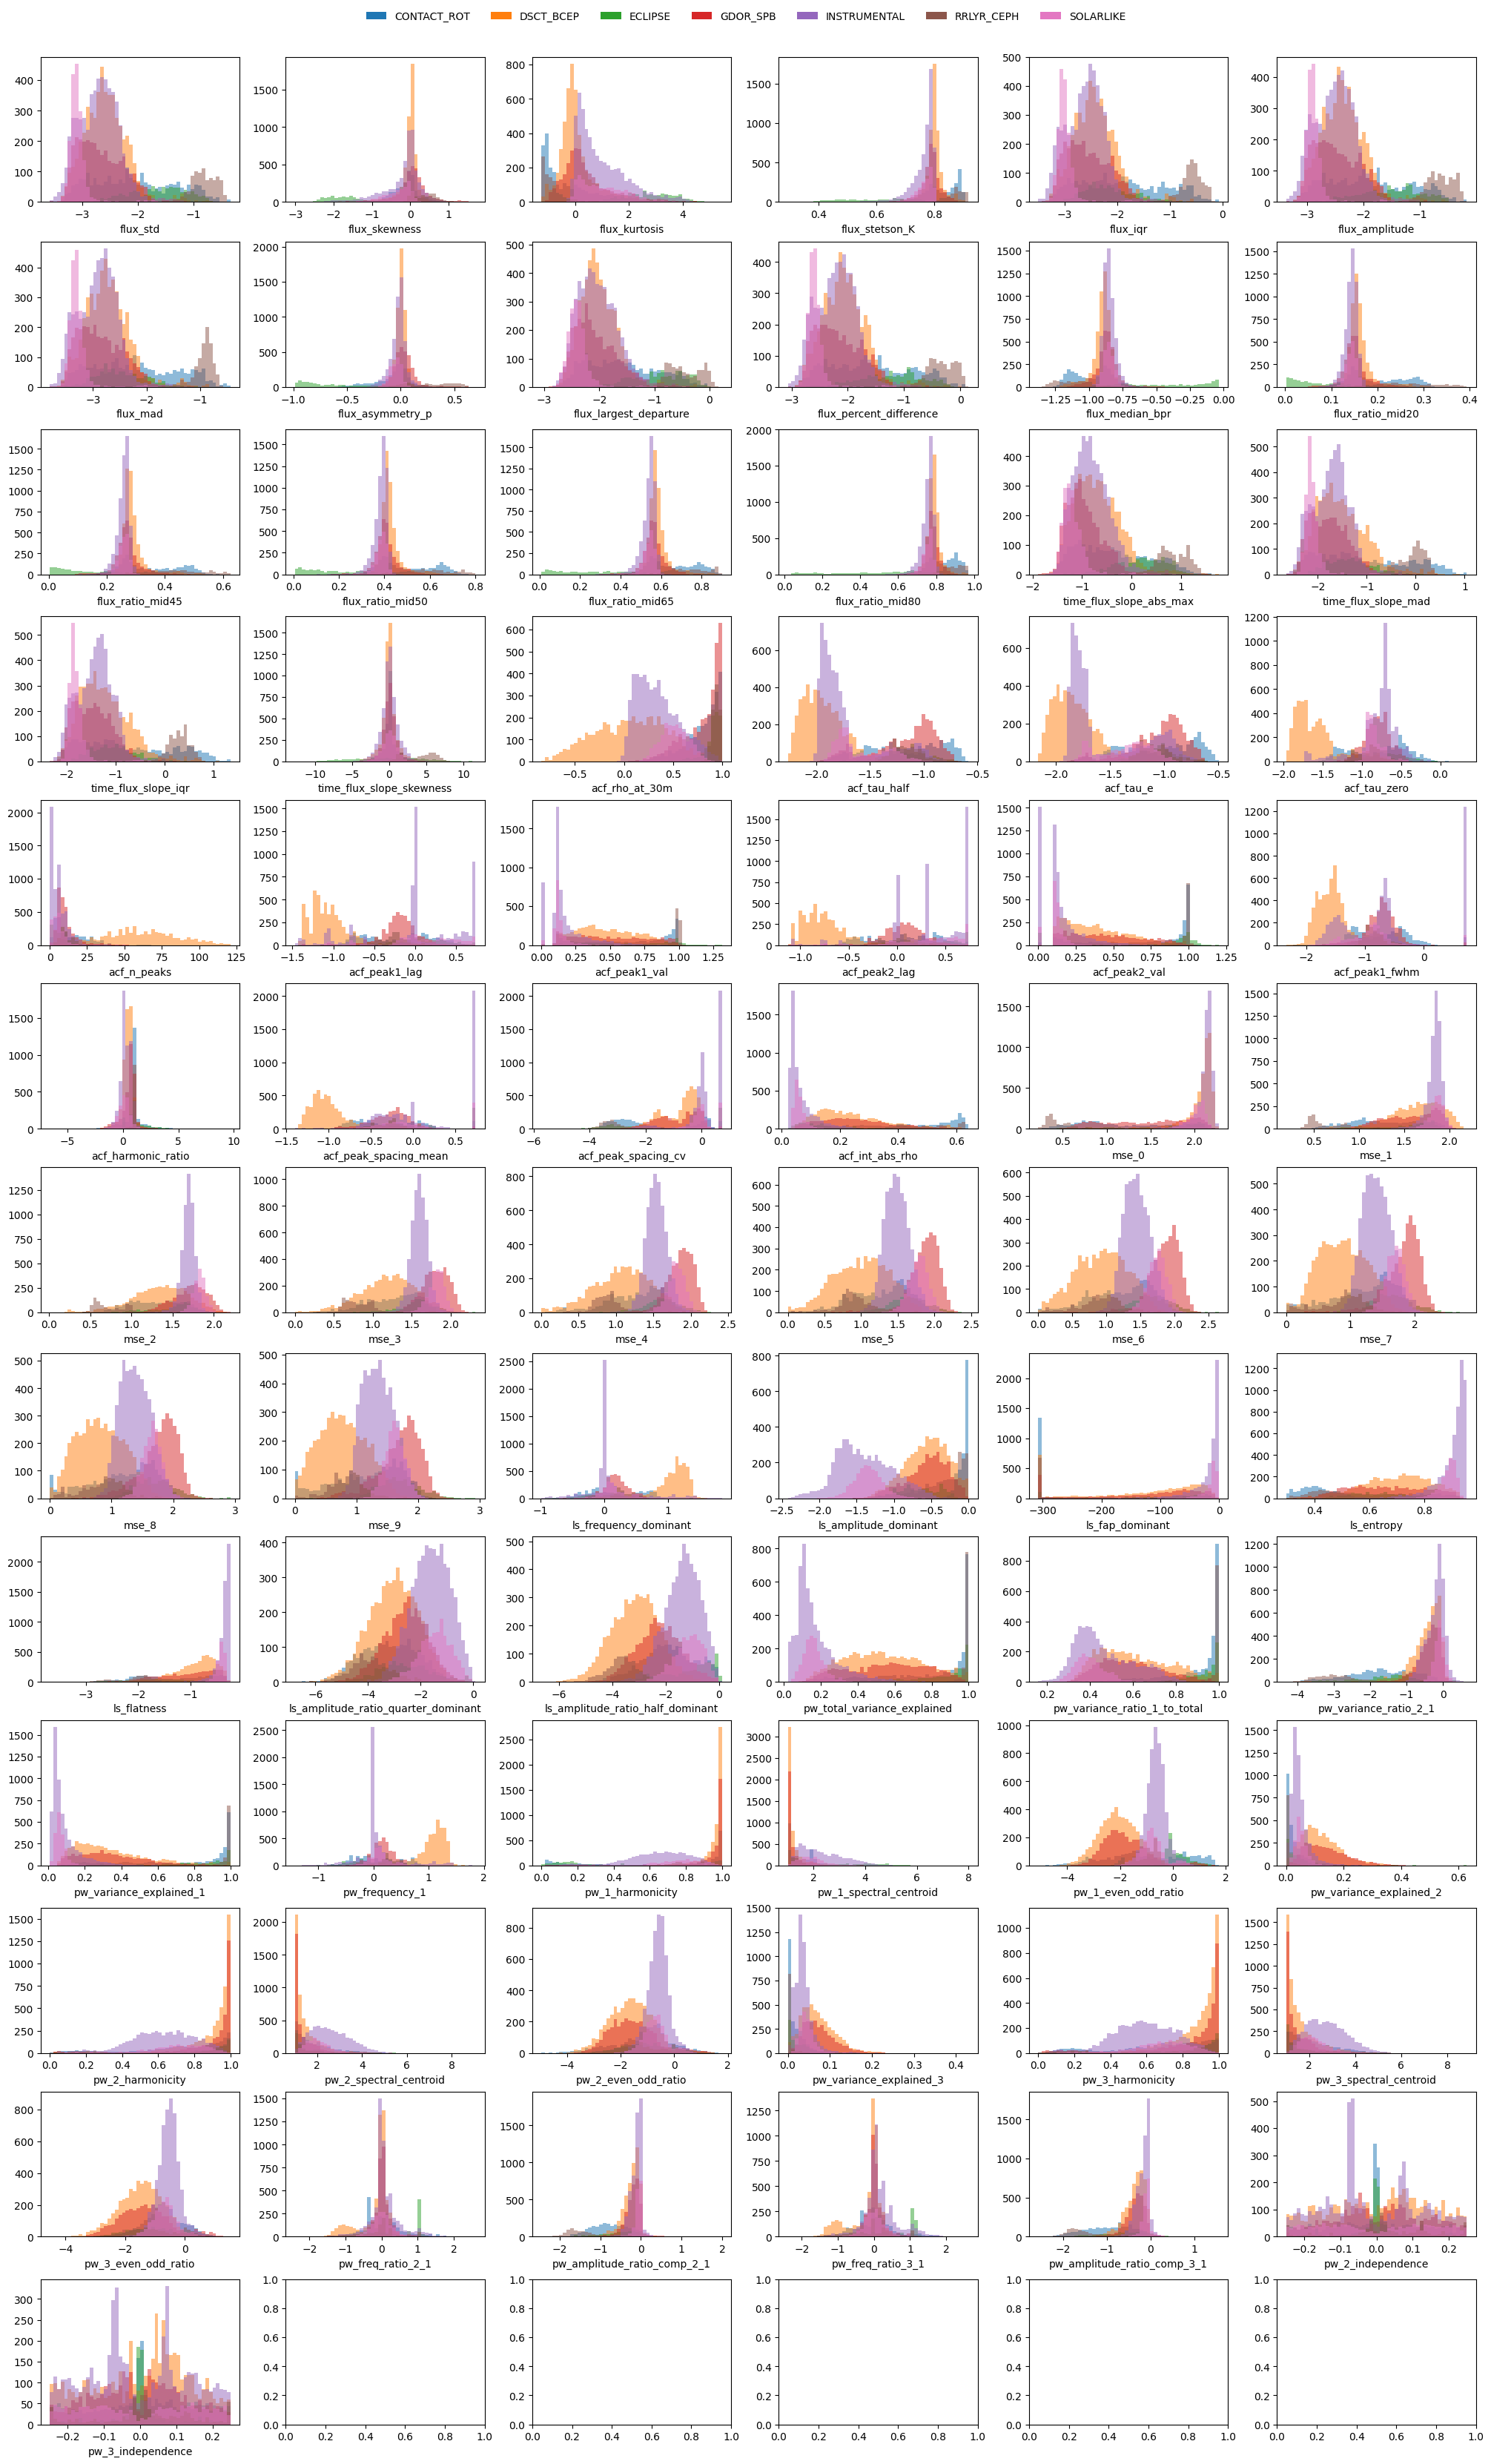

In [165]:
# Visualizing the features
bins = 50
n_rows = (X_fit.shape[1] + 6) // 6
fig, axs = plt.subplots(n_rows, 6, figsize=(20, 2.5*n_rows), constrained_layout=True)
for ax, col, col_name in zip(axs.ravel(), X_fit.T, X_names):
    hrange = (np.amin(col), np.amax(col))
    for name in y_names:
        mask = y_fit == name
        ax.hist(col[mask], range=hrange, bins=bins, label=name, alpha=0.5)
    ax.set_xlabel(col_name)

handles, labels = axs.ravel()[0].get_legend_handles_labels()
leg = fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.02), frameon=False)
for h in leg.legend_handles:
    h.set_alpha(1.0)

## Feature relevance/redundancy

In [171]:
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

corr = np.corrcoef(X_fit, rowvar=False)
dist = 1 - np.abs(corr)
dist = 0.5 * (dist + dist.T)
np.fill_diagonal(dist, 0.0)

link = linkage(squareform(dist), method='average')
clusters = fcluster(link, t=0.01, criterion='distance') # 99% correlation

selected_features = []
for c in np.unique(clusters):
    idx = np.where(clusters == c)[0]
    print(c, [X_names[i].item() for i in idx])
    selected_features.append(idx[0]) # Choose first, how to best do this?
selected_features = np.sort(np.array(selected_features))
#X_fit = X_fit[:, selected_features]
#X_test  = X_test[:, selected_features]
#with open(save_path / 'selected_features.pkl', "wb") as f:
#    dump(selected_features, f, protocol=5)

1 ['pw_freq_ratio_2_1']
2 ['pw_freq_ratio_3_1']
3 ['pw_variance_explained_2']
4 ['pw_variance_explained_3']
5 ['pw_3_harmonicity']
6 ['pw_3_even_odd_ratio']
7 ['pw_3_spectral_centroid']
8 ['pw_2_harmonicity']
9 ['pw_2_spectral_centroid']
10 ['pw_2_even_odd_ratio']
11 ['mse_8']
12 ['mse_9']
13 ['mse_6']
14 ['mse_7']
15 ['mse_4']
16 ['mse_5']
17 ['mse_3']
18 ['mse_2']
19 ['acf_tau_half']
20 ['acf_tau_e']
21 ['acf_rho_at_30m']
22 ['ls_frequency_dominant']
23 ['pw_frequency_1']
24 ['acf_tau_zero']
25 ['acf_n_peaks']
26 ['acf_peak1_lag']
27 ['acf_peak2_lag']
28 ['acf_peak_spacing_mean']
29 ['acf_peak1_fwhm']
30 ['pw_1_harmonicity']
31 ['pw_1_even_odd_ratio']
32 ['pw_1_spectral_centroid']
33 ['ls_amplitude_ratio_half_dominant']
34 ['flux_skewness']
35 ['flux_asymmetry_p']
36 ['flux_kurtosis']
37 ['flux_stetson_K']
38 ['flux_ratio_mid45']
39 ['flux_ratio_mid50']
40 ['flux_ratio_mid20']
41 ['flux_ratio_mid65']
42 ['flux_median_bpr']
43 ['flux_ratio_mid80']
44 ['flux_iqr', 'flux_mad']
45 ['time

In [172]:
%%time
from sklearn.feature_selection import mutual_info_classif

MI = mutual_info_classif(X_fit, y_fit, n_neighbors=3, copy=True, random_state=1234, n_jobs=16)

CPU times: user 358 ms, sys: 36 ms, total: 394 ms
Wall time: 797 ms


In [173]:
sort_mi = np.argsort(MI)[::-1]
for name, mi_ in zip(X_names[sort_mi], MI[sort_mi]):
    print(f"{mi_:0.4f} : {name:40}")

0.9686 : pw_frequency_1                          
0.9683 : ls_frequency_dominant                   
0.8666 : acf_peak2_lag                           
0.8561 : acf_peak1_lag                           
0.7636 : acf_peak_spacing_mean                   
0.6554 : acf_n_peaks                             
0.6478 : pw_variance_explained_1                 
0.6309 : pw_total_variance_explained             
0.6255 : ls_amplitude_dominant                   
0.5906 : acf_rho_at_30m                          
0.5887 : ls_entropy                              
0.5877 : acf_tau_half                            
0.5868 : acf_int_abs_rho                         
0.5774 : acf_tau_e                               
0.5703 : acf_tau_zero                            
0.5637 : mse_4                                   
0.5616 : ls_flatness                             
0.5605 : acf_peak1_fwhm                          
0.5530 : mse_5                                   
0.5498 : acf_peak_spacing_cv                     


# Classifiers

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

le = LabelEncoder().fit(y_fit)

with open(save_path / 'label_encoder.pkl', "wb") as f:
    dump(le, f, protocol=5)

## K-nn

In [174]:
# k-nn classifier, macro f1 record: 0.896

pipeline = Pipeline([
    ('scaler', RobustScaler()),
    ('classifier', KNeighborsClassifier(n_jobs=1))
])

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1234)
param_grid={'classifier__n_neighbors': [15, 25], 'classifier__weights': ['uniform', 'distance']}

clf = GridSearchCV(pipeline, param_grid=param_grid, cv=cv, scoring='f1_macro', n_jobs=4)
clf.fit(X_fit, le.transform(y_fit), groups=groups_fit)

print(classification_report(y_true=y_test, y_pred=le.inverse_transform(clf.predict(X_test)), digits=3))

              precision    recall  f1-score   support

 CONTACT_ROT      0.972     0.824     0.892       624
   DSCT_BCEP      0.972     0.959     0.966      1316
     ECLIPSE      0.959     0.925     0.941       200
    GDOR_SPB      0.902     0.905     0.903       810
INSTRUMENTAL      0.909     0.967     0.937      1496
  RRLYR_CEPH      0.991     1.000     0.996       227
   SOLARLIKE      0.852     0.884     0.868       535

    accuracy                          0.929      5208
   macro avg      0.937     0.923     0.929      5208
weighted avg      0.931     0.929     0.929      5208



In [12]:
# Best hyperparameters 
pl.DataFrame(clf.cv_results_).sort('rank_test_score').drop(['^.*_time$', 'params'])

param_classifier__n_neighbors,param_classifier__weights,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
i64,str,f64,f64,f64,f64,f64,f64,f64,i32
15,"""uniform""",0.926728,0.900331,0.907729,0.898162,0.921348,0.91086,0.011346,1
15,"""distance""",0.92741,0.899776,0.907837,0.897701,0.921323,0.910809,0.011735,2
25,"""distance""",0.924645,0.899082,0.902456,0.893194,0.919595,0.907795,0.012172,3
25,"""uniform""",0.923656,0.899159,0.903328,0.893014,0.919815,0.907794,0.011909,4


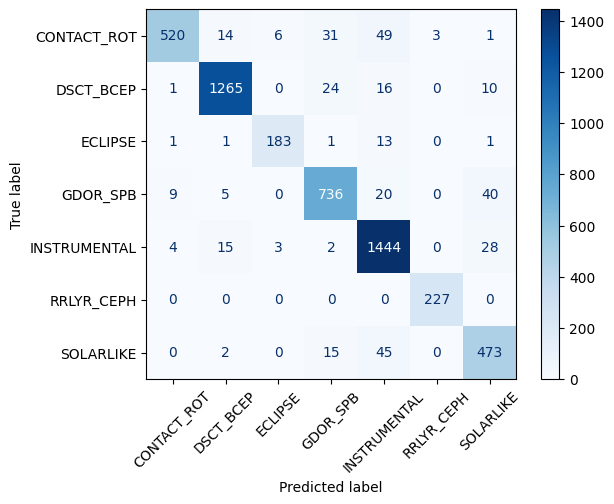

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay

y_test_pred = le.inverse_transform(clf.predict(X_test))
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_test_pred, cmap=plt.cm.Blues, xticks_rotation=45)

## XGBOOST

In [39]:
y_fit_encoded = le.transform(y_fit)

baseline = XGBClassifier(
    objective='multi:softprob',
    eval_metric='mlogloss',
    tree_method='hist',
    n_jobs=8,
    random_state=1234,
)
baseline.fit(X_fit, y_fit_encoded)
train_f1 = f1_score(y_fit_encoded, baseline.predict(X_fit), average='macro')
test_f1 = f1_score(le.transform(y_test), baseline.predict(X_test), average='macro')
print(f"Train F1: {train_f1:.3f}  |  Test F1: {test_f1:.3f}  |  Gap: {train_f1 - test_f1:.3f}")
print(classification_report(y_true=y_test, y_pred=le.inverse_transform(baseline.predict(X_test)), digits=3))

Train F1: 1.000  |  Test F1: 0.967  |  Gap: 0.033
              precision    recall  f1-score   support

 CONTACT_ROT      0.973     0.925     0.948       624
   DSCT_BCEP      0.993     0.990     0.992      1316
     ECLIPSE      0.956     0.980     0.968       200
    GDOR_SPB      0.934     0.960     0.947       810
INSTRUMENTAL      0.968     0.985     0.976      1496
  RRLYR_CEPH      1.000     1.000     1.000       227
   SOLARLIKE      0.953     0.918     0.935       535

    accuracy                          0.969      5208
   macro avg      0.968     0.965     0.967      5208
weighted avg      0.969     0.969     0.969      5208



In [76]:
%%time

# XGBoost, macro f1 record: 0.918 (v1), 0.932 (v1.5)

import optuna
from sklearn.model_selection import cross_val_score

class EarlyStoppingCallback:
    def __init__(self, patience=25):
        self.patience = patience
        self.best_value = -np.inf
        self.trials_without_improvement = 0

    def __call__(self, study, trial):
        if trial.value > self.best_value:
            self.best_value = trial.value
            self.trials_without_improvement = 0
        else:
            self.trials_without_improvement += 1

        if self.trials_without_improvement >= self.patience:
            study.stop()

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1234)
y_fit_encoded = le.transform(y_fit)

def objective(trial):
    params = {
        'max_depth': trial.suggest_int('max_depth', 3, 12), # Default: 6
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10), # Default: 1
        'gamma': trial.suggest_float('gamma', 1e-4, 5.0, log=True), # Default: 0
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True), # Default: 1
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True), # Default: 0
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 1.0, log=True), # Default: 0.3
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
    }
    clf = XGBClassifier(
        **params,
        n_estimators=800,
        objective='multi:softprob',
        eval_metric='mlogloss',
        tree_method='hist',
        n_jobs=8,
        random_state=1234,
    )
    scores = cross_val_score(clf, X_fit, y_fit_encoded, cv=cv, groups=groups_fit, scoring='f1_macro', n_jobs=5)
    return scores.mean()

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=1234))
study.optimize(objective, n_trials=200, callbacks=[EarlyStoppingCallback(patience=25)])
print(f"Stopped at trial {len(study.trials)}")
print("Best params:", study.best_params)
print("Best CV F1 macro:", study.best_value)
# Stage 2: Find optimal n_estimators with early stopping
X_train, X_val, y_train, y_val = train_test_split(
    X_fit, y_fit_encoded, test_size=0.15, stratify=y_fit_encoded, random_state=1234,
)
final_clf = XGBClassifier(
    **study.best_params,
    n_estimators=3000,
    objective='multi:softprob',
    eval_metric='mlogloss',
    tree_method='hist',
    early_stopping_rounds=100,
    n_jobs=8,
    random_state=1234,
)
final_clf.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
print(f"Optimal n_estimators: {final_clf.best_iteration}")
# Stage 3: Retrain on full training set with that exact tree count
final_clf = XGBClassifier(
    **study.best_params,
    n_estimators=final_clf.best_iteration,
    objective='multi:softprob',
    eval_metric='mlogloss',
    tree_method='hist',
    n_jobs=8,
    random_state=1234,
)
final_clf.fit(X_fit, y_fit_encoded)
train_f1 = f1_score(y_fit_encoded, final_clf.predict(X_fit), average='macro')
test_f1 = f1_score(le.transform(y_test), final_clf.predict(X_test), average='macro')
print(f"Train F1: {train_f1:.3f}  |  Test F1: {test_f1:.3f}  |  Gap: {train_f1 - test_f1:.3f}")
print(classification_report(y_true=y_test, y_pred=le.inverse_transform(final_clf.predict(X_test)), digits=3))

[I 2026-05-11 12:01:40,771] A new study created in memory with name: no-name-003af4c7-c000-4aa0-92ed-11c06be997ff
[I 2026-05-11 12:02:06,769] Trial 0 finished with value: 0.9566394390385063 and parameters: {'max_depth': 4, 'min_child_weight': 7, 'gamma': 0.011399072494958107, 'reg_lambda': 0.8448758931656905, 'reg_alpha': 0.7941070297668178, 'learning_rate': 0.03509014885796852, 'colsample_bytree': 0.7829392765429289, 'subsample': 0.9405616532605058}. Best is trial 0 with value: 0.9566394390385063.
[I 2026-05-11 12:02:20,794] Trial 1 finished with value: 0.9561864929555582 and parameters: {'max_depth': 12, 'min_child_weight': 9, 'gamma': 0.004801452298233113, 'reg_lambda': 0.03198715594382152, 'reg_alpha': 0.261405472864251, 'learning_rate': 0.2663201666850019, 'colsample_bytree': 0.8110752264371185, 'subsample': 0.8683588558196875}. Best is trial 0 with value: 0.9566394390385063.
[I 2026-05-11 12:02:31,970] Trial 2 finished with value: 0.955357172816621 and parameters: {'max_depth': 8

Stopped at trial 120
Best params: {'max_depth': 3, 'min_child_weight': 1, 'gamma': 0.00010512161753881675, 'reg_lambda': 0.051179899996636205, 'reg_alpha': 0.04399922708617159, 'learning_rate': 0.19865964920880175, 'colsample_bytree': 0.730629199846283, 'subsample': 0.8717271985188604}
Best CV F1 macro: 0.9602145415977356
Optimal n_estimators: 176
Train F1: 0.998  |  Test F1: 0.965  |  Gap: 0.033
              precision    recall  f1-score   support

 CONTACT_ROT      0.967     0.926     0.946       624
   DSCT_BCEP      0.990     0.989     0.989      1316
     ECLIPSE      0.956     0.980     0.968       200
    GDOR_SPB      0.930     0.957     0.943       810
INSTRUMENTAL      0.968     0.983     0.976      1496
  RRLYR_CEPH      1.000     1.000     1.000       227
   SOLARLIKE      0.955     0.914     0.934       535

    accuracy                          0.967      5208
   macro avg      0.967     0.964     0.965      5208
weighted avg      0.967     0.967     0.967      5208

CPU

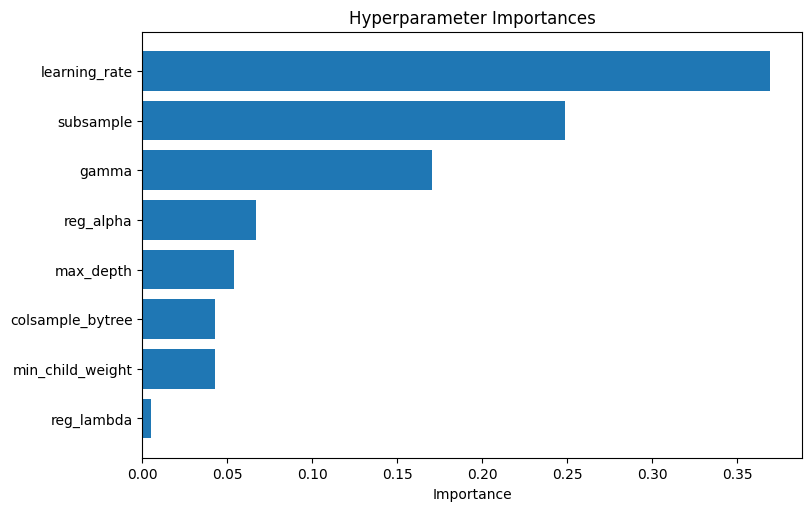

In [78]:
importances = optuna.importance.get_param_importances(study)
params = list(importances.keys())
values = list(importances.values())

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.barh(params[::-1], values[::-1])
ax.set_xlabel('Importance')
ax.set_title('Hyperparameter Importances')
ax.tick_params(axis='y')

In [ ]:
calibrated_clf = CalibratedClassifierCV(
    final_clf, method="isotonic", cv="prefit"
)
calibrated_clf.fit(X_cal, y_cal)

Text(0.5, 1.0, 'Full dataset')

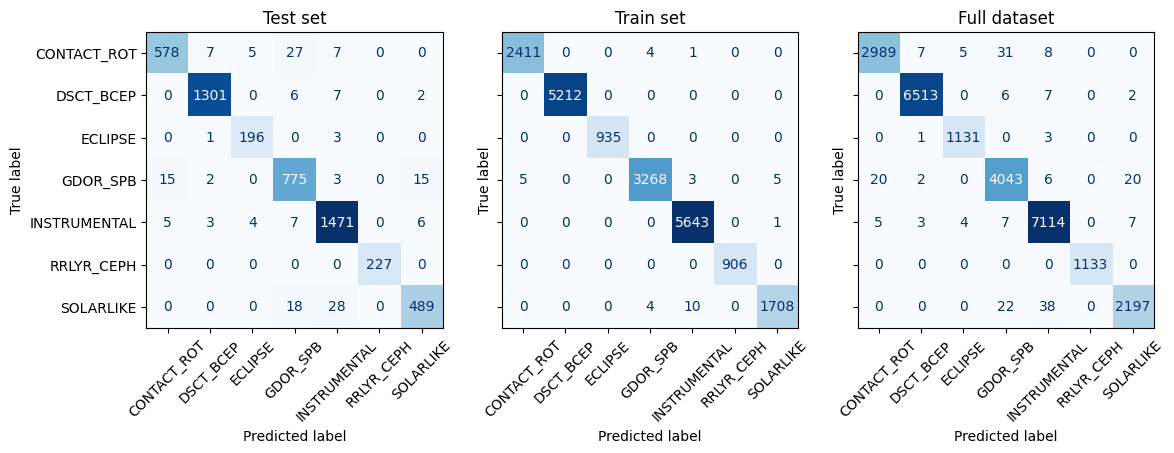

In [79]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
y_test_pred = le.inverse_transform(final_clf.predict(X_test))
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_test_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[0], colorbar=False)
axs[0].set_title('Test set')
y_fit_pred = le.inverse_transform(final_clf.predict(X_fit))
ConfusionMatrixDisplay.from_predictions(y_true=y_fit, y_pred=y_fit_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[1], colorbar=False)
axs[1].set_title('Train set')
ConfusionMatrixDisplay.from_predictions(y_true=np.concatenate([y_fit, y_test]), y_pred=np.concatenate([y_fit_pred, y_test_pred], axis=0), cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[2], colorbar=False)
axs[2].set_title('Full dataset')

Text(0.5, 1.0, 'Full dataset')

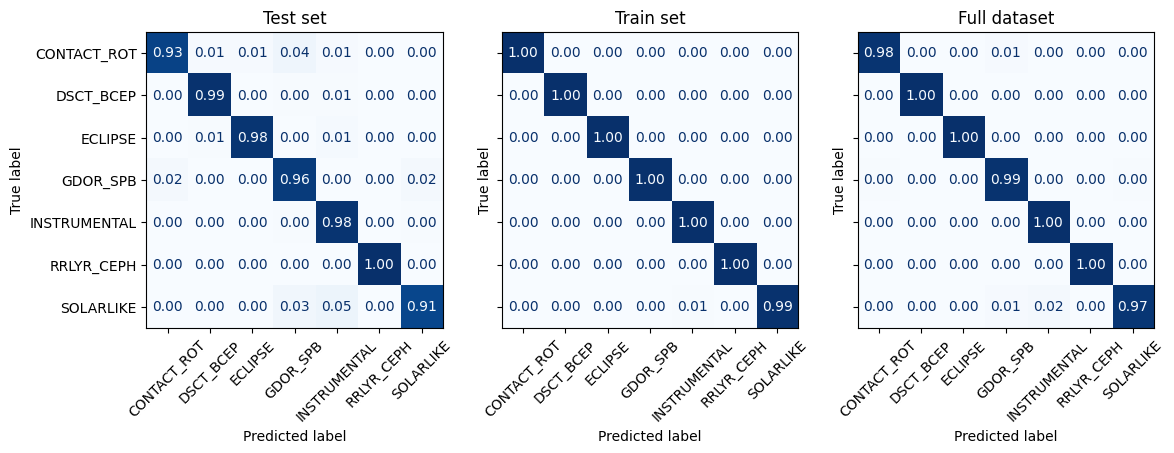

In [80]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
y_test_pred = le.inverse_transform(final_clf.predict(X_test))
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_test_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[0], colorbar=False, normalize='true', values_format='0.2f')
axs[0].set_title('Test set')
y_fit_pred = le.inverse_transform(final_clf.predict(X_fit))
ConfusionMatrixDisplay.from_predictions(y_true=y_fit, y_pred=y_fit_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[1], colorbar=False, normalize='true', values_format='0.2f')
axs[1].set_title('Train set')
ConfusionMatrixDisplay.from_predictions(y_true=np.concatenate([y_fit, y_test]), y_pred=np.concatenate([y_fit_pred, y_test_pred], axis=0), cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[2], colorbar=False, normalize='true', values_format='0.2f')
axs[2].set_title('Full dataset')

### Feature importance

CPU times: user 4 s, sys: 87.9 ms, total: 4.09 s
Wall time: 14.1 s


Text(0.5, 1.0, 'Permutation-based feature importance')

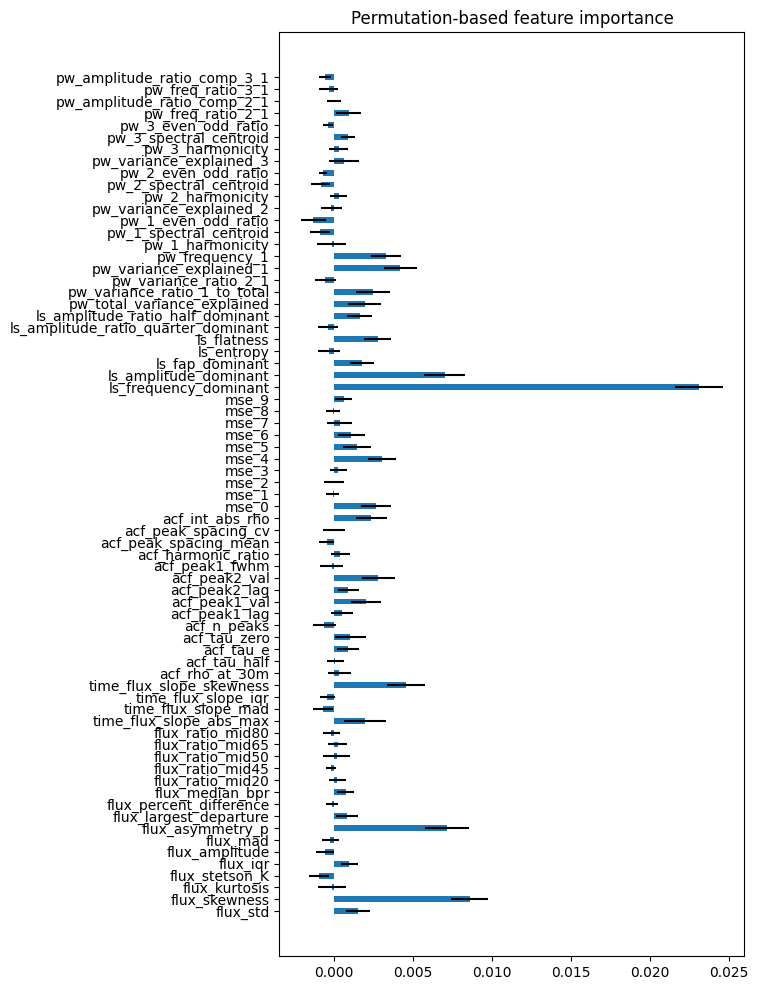

In [81]:
%%time
from sklearn.inspection import permutation_importance

# Permutation importance drawbacks:
# Underestimates importance under feature correlation.
# If two features encode the same information, permuting one may not hurt performance.

pi_global = permutation_importance(final_clf, X_test, le.transform(y_test), scoring="f1_macro", n_repeats=30, random_state=0, n_jobs=16)

fig, ax = plt.subplots(figsize=(6, 12))
ax.barh(y=np.array(X_names), width=pi_global.importances_mean, xerr=pi_global.importances_std, height=0.5)
ax.set_title('Permutation-based feature importance')

CPU times: user 4.61 s, sys: 92.2 ms, total: 4.7 s
Wall time: 9.75 s


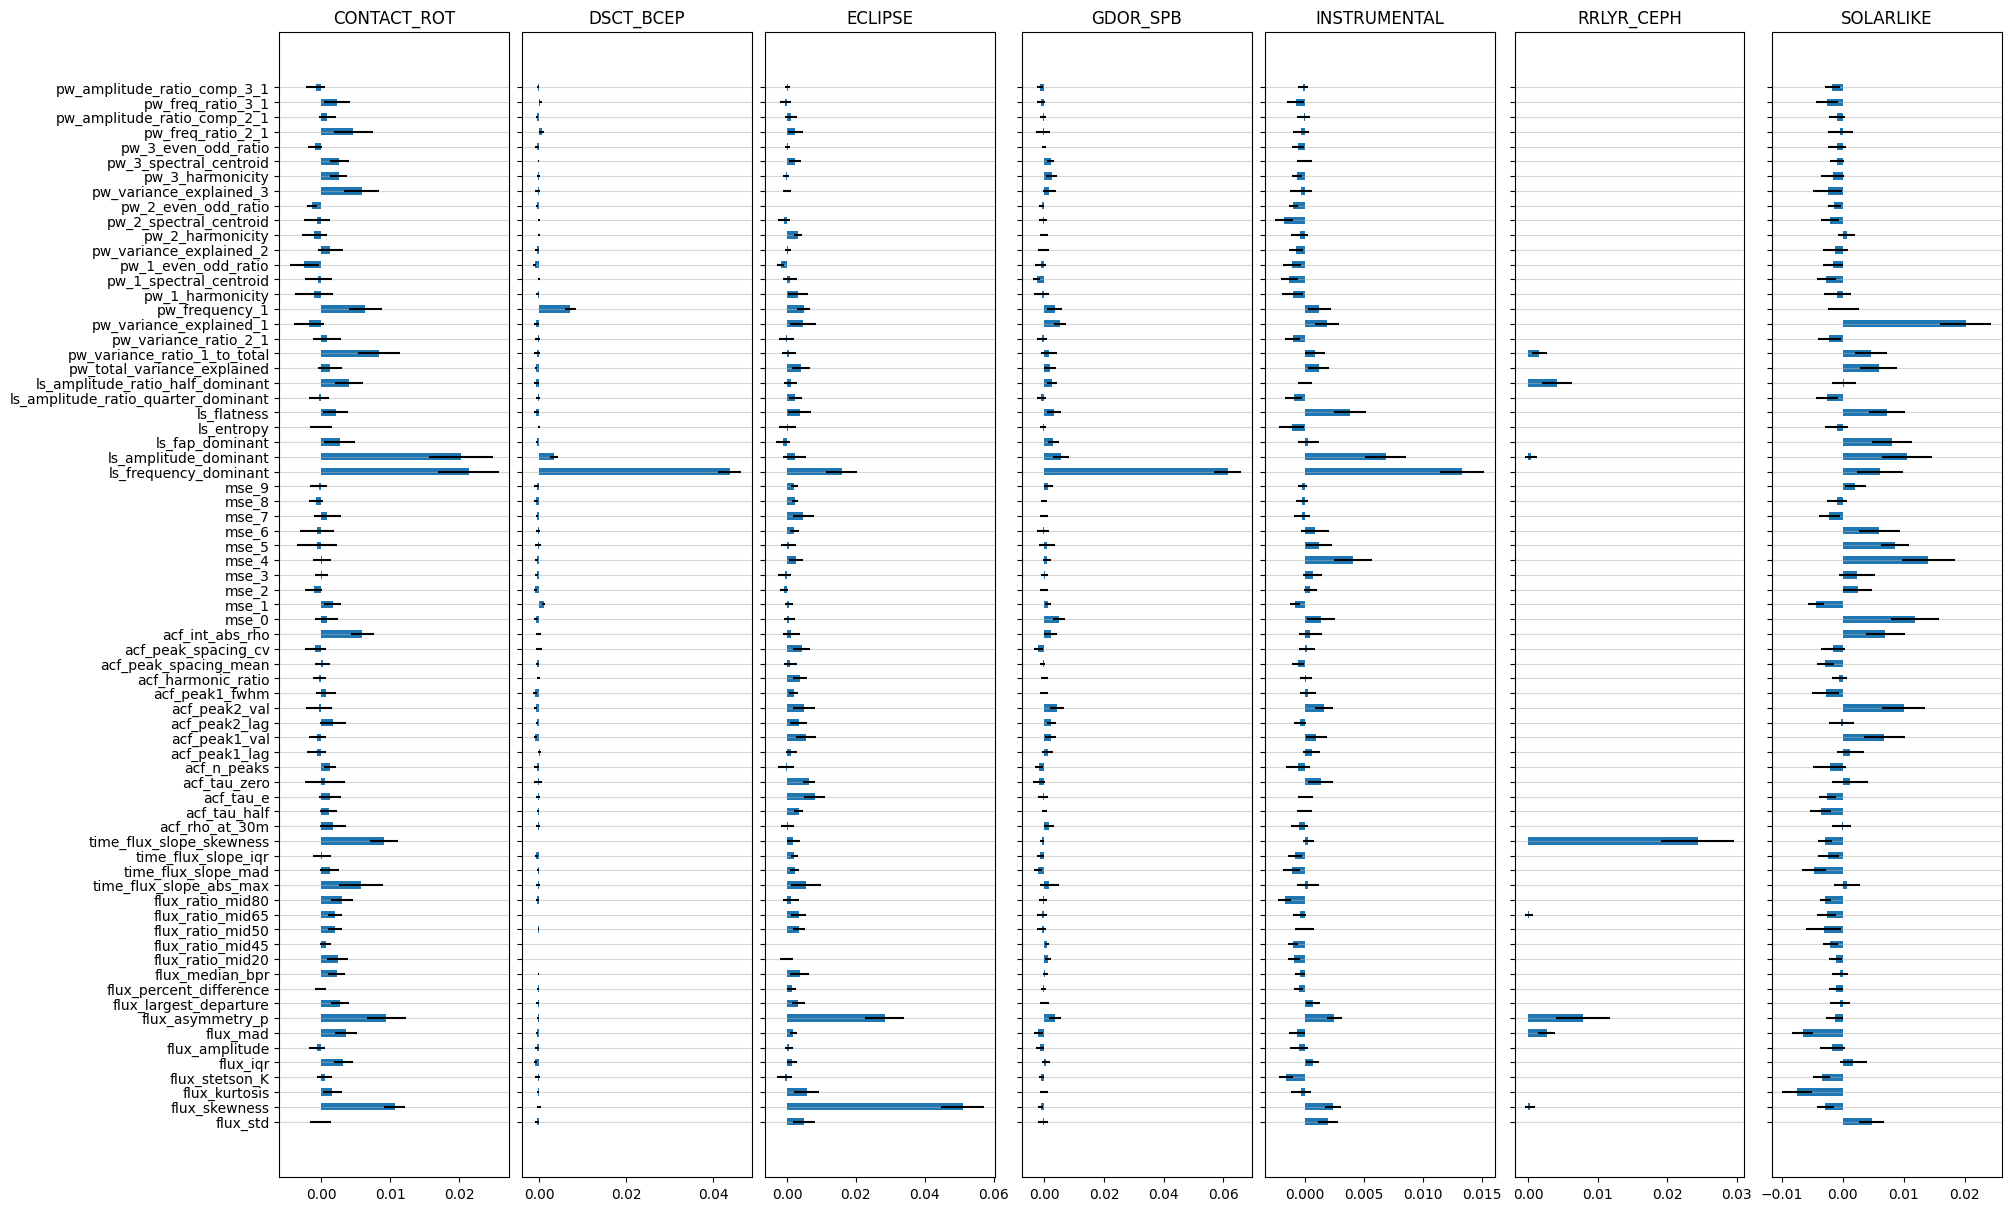

In [82]:
%%time
from sklearn.metrics import f1_score

classes = np.unique(le.transform(y_test))

def per_class_f1_scorer(estimator, X, y):
    y_pred = estimator.predict(X)
    return np.array([f1_score(y == c, y_pred == c, zero_division=0) for c in classes], dtype=float)

pi_class = permutation_importance(final_clf, X_test, le.transform(y_test), scoring=per_class_f1_scorer, n_repeats=30, random_state=0, n_jobs=16)

fig, axs = plt.subplots(1, len(classes), figsize=(20, 12), sharey=True, constrained_layout=True)
for ax, name, pi_class_mean, pi_class_std in zip(axs, classes, pi_class.importances_mean.T, pi_class.importances_std.T):
    ax.barh(y=np.array(X_names), width=pi_class_mean, xerr=pi_class_std, height=0.5)
    ax.set_title(le.inverse_transform([name]).item())
    ax.grid(axis='y', alpha=0.5)

### Calibration

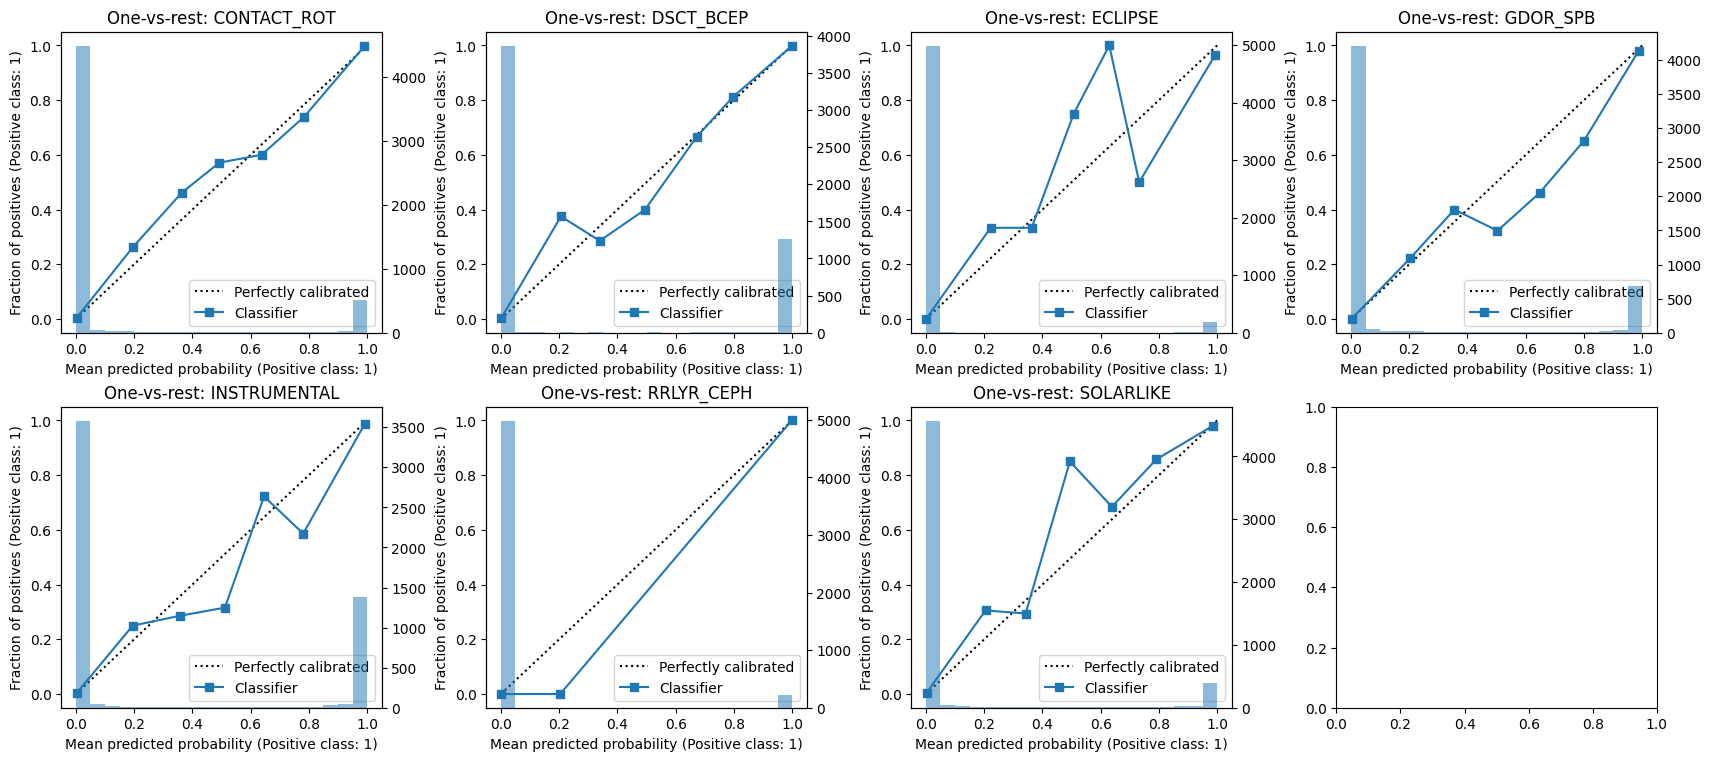

In [183]:
# How good is the calibration of the model?

from sklearn.calibration import CalibrationDisplay

#est = baseline 
est = final_clf
proba = est.predict_proba(X_test)
classes = est.classes_
fig, axs = plt.subplots(2, len(classes)//2+1, figsize=(17, 7.5), sharey=False, constrained_layout=True)

for ax, c in zip(np.atleast_1d(axs.ravel()), classes):
    k = np.where(classes == c)[0][0]
    y_bin = (le.transform(y_test) == c).astype(int)
    p_c = proba[:, k]
    cdisplay = CalibrationDisplay.from_predictions(y_true=y_bin, y_prob=p_c, n_bins=7, strategy="uniform", ax=ax)
    ax.set_title(f"One-vs-rest: {le.inverse_transform(np.array([c]))[0]}")
    ax.twinx().hist(cdisplay.y_prob, range=(0, 1), bins=20, alpha=0.5)

## Export best training set predictions and best classifier

In [95]:
from training import prepare_predictions_dataframe

df_pred = prepare_predictions_dataframe(final_clf, le, X=X_all, paths=paths_all, drop_nans=True)
df_pred.head()
df_pred.write_parquet(save_path / 'predictions.parquet')

with open(save_path / 'model_xgboost.pkl', "wb") as f:
    dump(final_clf, f, protocol=5)

## Visualization of feature space

In [ ]:
df_pred = pl.read_parquet(save_path / 'predictions.parquet')
df_pred


In [ ]:
%%time
from umap import UMAP

pipeline_umap = Pipeline([
    ('scaler', RobustScaler()),
    ('projector',  UMAP(n_components=2, min_dist=0.0, negative_sample_rate=10, metric='euclidean', n_jobs=8, n_neighbors=25))
])

X_proj = pipeline_umap.fit_transform(X_all)
fig, ax = plt.subplots(figsize=(10, 8), dpi=120)

for name in y_names:
    mask = y_all == name
    ax.scatter(X_proj[mask, 0], X_proj[mask, 1], s=1, label=name, alpha=0.5)
leg = plt.legend()
for lh in leg.legend_handles:
    lh.set_alpha(1)
    lh._sizes = [10]

In [ ]:
df_hv = pl.DataFrame({'lambda_1': X_proj[:, 0], 'lambda_2': X_proj[:, 1], 'class': y_all, 'path': paths_all})
df_hv = df_hv.join(df_training_features.select(['path', 'GaiaID', 'ls_frequency_dominant']), on='path')
df_hv.write_parquet(save_path / 'viz_v2.parquet')

## Error analysis

In [96]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from light_curves import read_fits_lc, preprocess_lc
from periodogram_features import compute_periodogram
from config import PipelineConfig

cfg = PipelineConfig()

def plot_misclasifications(true_class, pred_class, max_examples: int = 10, verbose=False):
    df_analysis = df_pred.join(df_training_set.select(['path','label']), on='path').filter(
        pl.col('label').eq(true_class) & pl.col('best_class').eq(pred_class)
    ).with_columns(
        pl.col('path').str.split('-').list.get(2).alias('sid'),
        pl.col('path').str.split('-').list.get(3).alias('sector')
    ).sort(['sid', 'sector'])
    total_lc = df_analysis.height
    df_analysis = df_analysis.unique('sid').sort('best_class', descending=True)
    total_sids = df_analysis.height
    print(f"Total LCs: {total_lc}, total sources: {total_sids}")
    if total_sids == 0:
        return
    if total_sids > max_examples:
        df_analysis = df_analysis.head(max_examples)
    total_rows = df_analysis.height
    fig, axs = plt.subplots(total_rows, 4, figsize=(16, 3*total_rows), constrained_layout=True, sharex=False)
    axs = np.atleast_2d(axs)
    for row, ax in zip(df_analysis.iter_rows(named=True), axs):
        path_, proba, entropy, proba_true = row['path'], row[pred_class], row['entropy'], row[true_class]
        sid, sector = path_.split('-')[2:4]
        if verbose:
            print(path_)
        ax[0].set_title(f"Gaia sid: {sid}, sector {sector}")
        ax[1].set_title(f"True: {true_class}={proba_true:0.3f}")
        ax[2].set_title(f"Pred: {pred_class}={proba:0.3f}, H={entropy:0.2f}")
        lc = read_fits_lc(path_)
        #ax[0].scatter(time, flux, s=1)
        time, flux = preprocess_lc(lc.time, lc.cal_flux, lc.sector, cfg.preprocessing)
        freq, ampl, _ = compute_periodogram(time, flux)
        best_freq = freq[np.argmax(ampl)]
        ax[0].scatter(time, flux, s=1)
        ax[-3].plot(freq, ampl)
        ax[-2].plot(freq[freq<5], ampl[freq<5])
        ax[-1].set_title(f"f={best_freq:0.4f}")
        ax[-1].scatter(np.mod(time, 2/best_freq)*best_freq, flux, s=1)
        
    ax[0].set_xlabel('Time [d]')
    ax[-3].set_xlabel('Frequency [1/d]')
    ax[-2].set_xlabel('Frequency [1/d]')
    ax[-1].set_xlabel('Phase');
    return df_analysis

#plot_misclasifications(true_class = 'CONTACT_ROT', pred_class = 'DSCT_BCEP', max_examples=6)

In [97]:
df_ = plot_misclasifications(true_class = 'RRLYR_CEPH', pred_class = 'CONTACT_ROT', max_examples=20)

Total LCs: 0, total sources: 0


In [98]:
df_ = plot_misclasifications(true_class = 'RRLYR_CEPH', pred_class = 'GDOR_SPB', max_examples=20)

Total LCs: 0, total sources: 0


In [99]:
plot_misclasifications(true_class = 'DSCT_BCEP', pred_class = 'CONTACT_ROT', max_examples=10)

Total LCs: 0, total sources: 0


Total LCs: 2, total sources: 1


path,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENTAL,RRLYR_CEPH,SOLARLIKE,best_class,entropy,best_proba,label,sid,sector
str,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,str,str,str
"""/STER/mamsie/tess/TIC/tglc_scr…",0.00015,0.501571,9.5922e-7,0.498235,0.000011,0.000001,0.000031,"""DSCT_BCEP""",0.357158,0.501571,"""GDOR_SPB""","""2261750329494838784""","""s0040"""


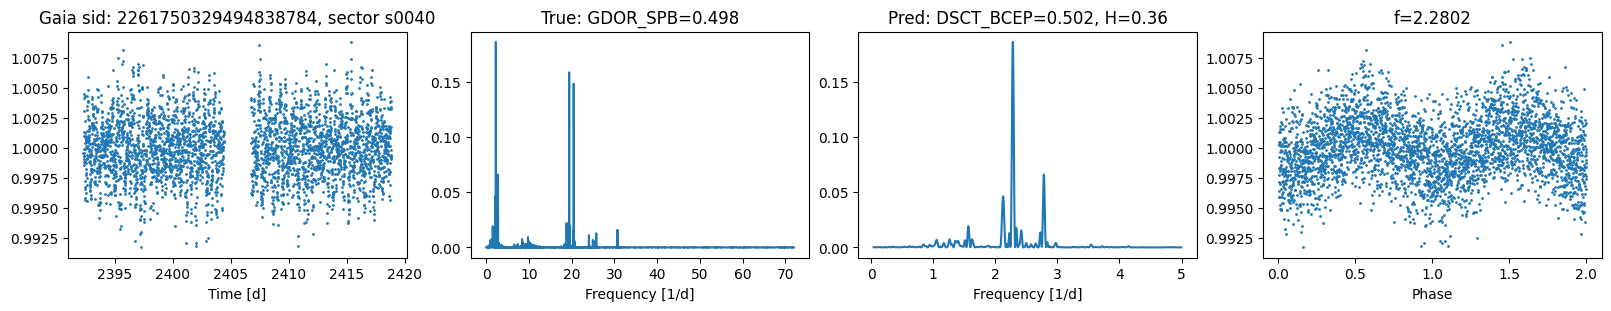

In [100]:
plot_misclasifications(true_class = 'GDOR_SPB', pred_class = 'DSCT_BCEP', max_examples=6)

Total LCs: 6, total sources: 4


path,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENTAL,RRLYR_CEPH,SOLARLIKE,best_class,entropy,best_proba,label,sid,sector
str,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,str,str,str
"""/STER/mamsie/tess/TIC/tglc_scr…",0.033843,0.060337,0.000353,0.857505,0.04076,0.000005,0.007197,"""GDOR_SPB""",0.300444,0.857505,"""DSCT_BCEP""","""1432984094208222720""","""s0018"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.019467,0.336679,0.000073,0.642389,0.001091,0.000177,0.000125,"""GDOR_SPB""",0.379402,0.642389,"""DSCT_BCEP""","""1630079696745880192""","""s0019"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000054,0.003249,0.000002,0.973399,0.000427,7.1607e-7,0.022869,"""GDOR_SPB""",0.069447,0.973399,"""DSCT_BCEP""","""2241835798797330816""","""s0014"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.001549,0.015425,0.000001,0.982997,0.000019,5.4575e-7,0.000009,"""GDOR_SPB""",0.047051,0.982997,"""DSCT_BCEP""","""2269509548691730944""","""s0014"""


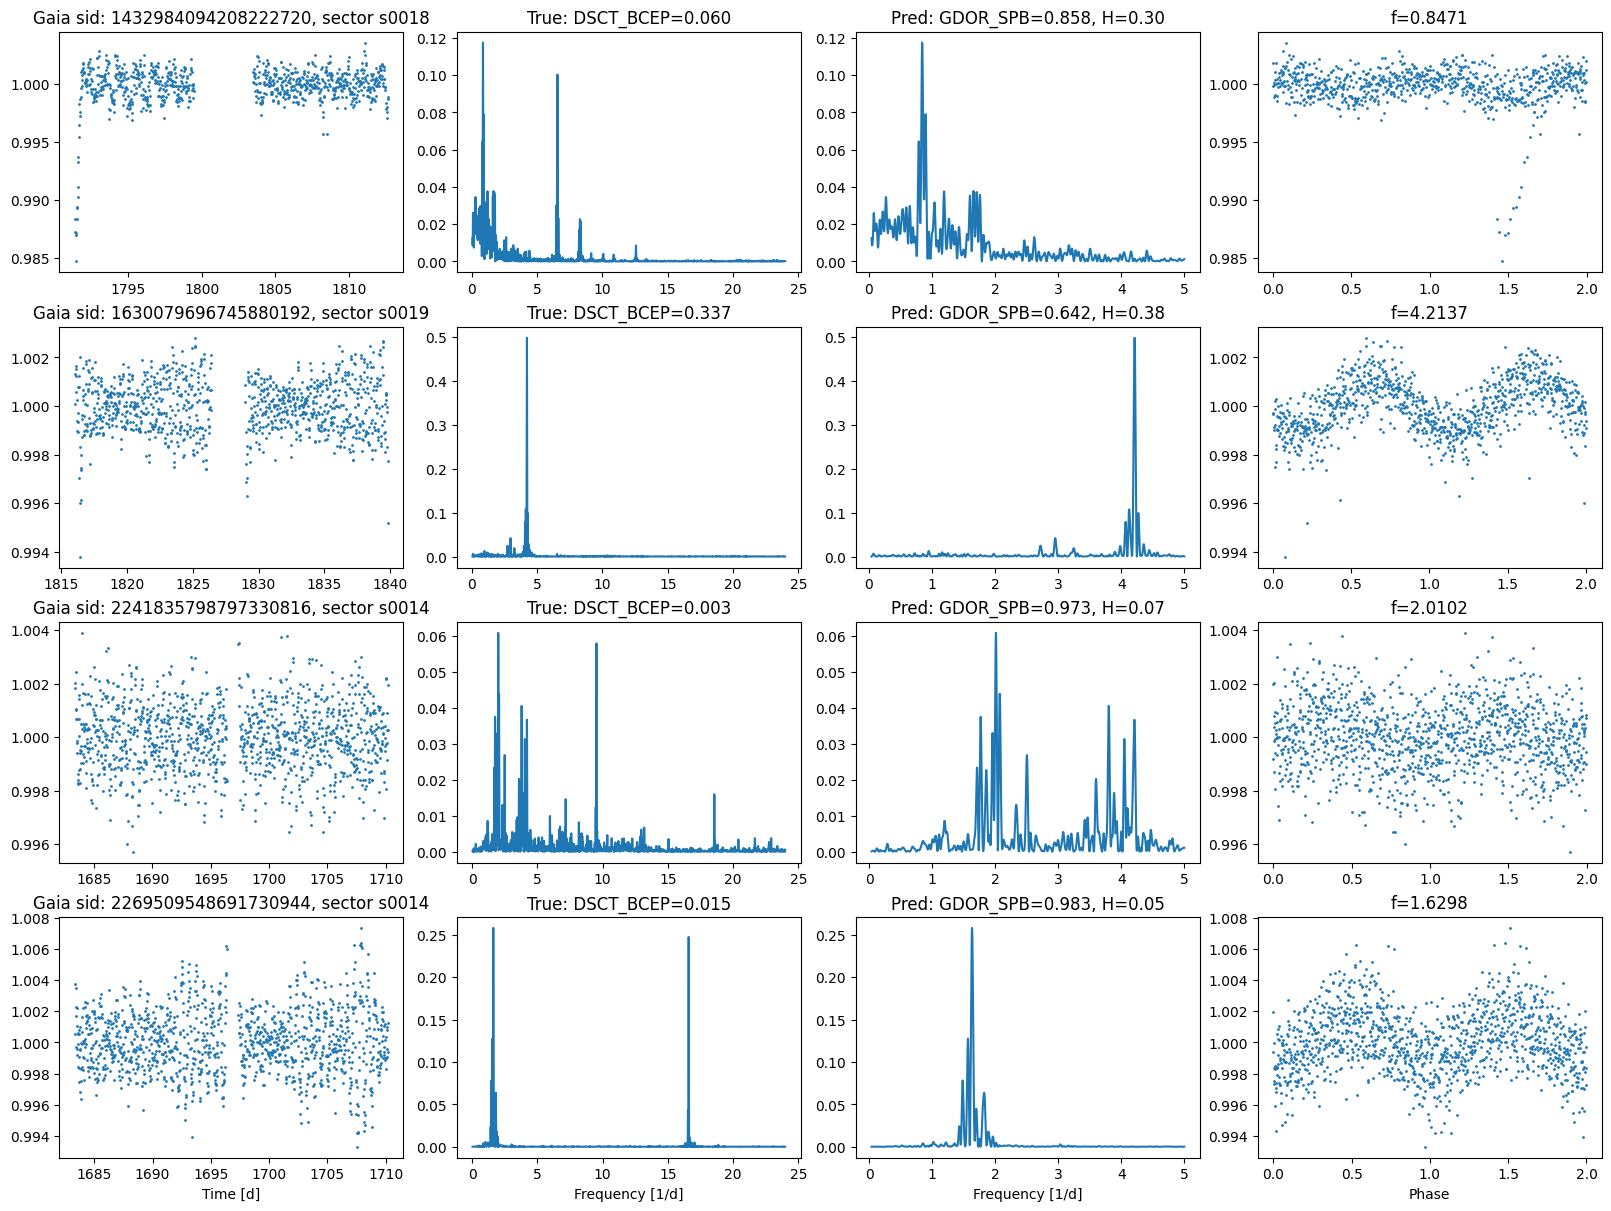

In [101]:
plot_misclasifications(true_class = 'DSCT_BCEP', pred_class = 'GDOR_SPB', max_examples=6)

In [102]:
plot_misclasifications(true_class = 'ECLIPSE', pred_class = 'CONTACT_ROT', max_examples=6)

Total LCs: 0, total sources: 0


Total LCs: 3, total sources: 3


path,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENTAL,RRLYR_CEPH,SOLARLIKE,best_class,entropy,best_proba,label,sid,sector
str,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,str,str,str
"""/STER/mamsie/tess/TIC/tglc_scr…",0.002556,0.002432,0.256553,0.003617,0.733683,0.000008,0.001152,"""INSTRUMENTAL""",0.325987,0.733683,"""ECLIPSE""","""1421469591829848192""","""s0020"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.00088,0.007615,0.374321,0.000695,0.616442,0.000007,0.000039,"""INSTRUMENTAL""",0.367399,0.616442,"""ECLIPSE""","""1647356632190121728""","""s0020"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000021,0.000186,0.025323,0.00009,0.974267,3.6621e-7,0.000112,"""INSTRUMENTAL""",0.062788,0.974267,"""ECLIPSE""","""2085670964017513856""","""s0014"""


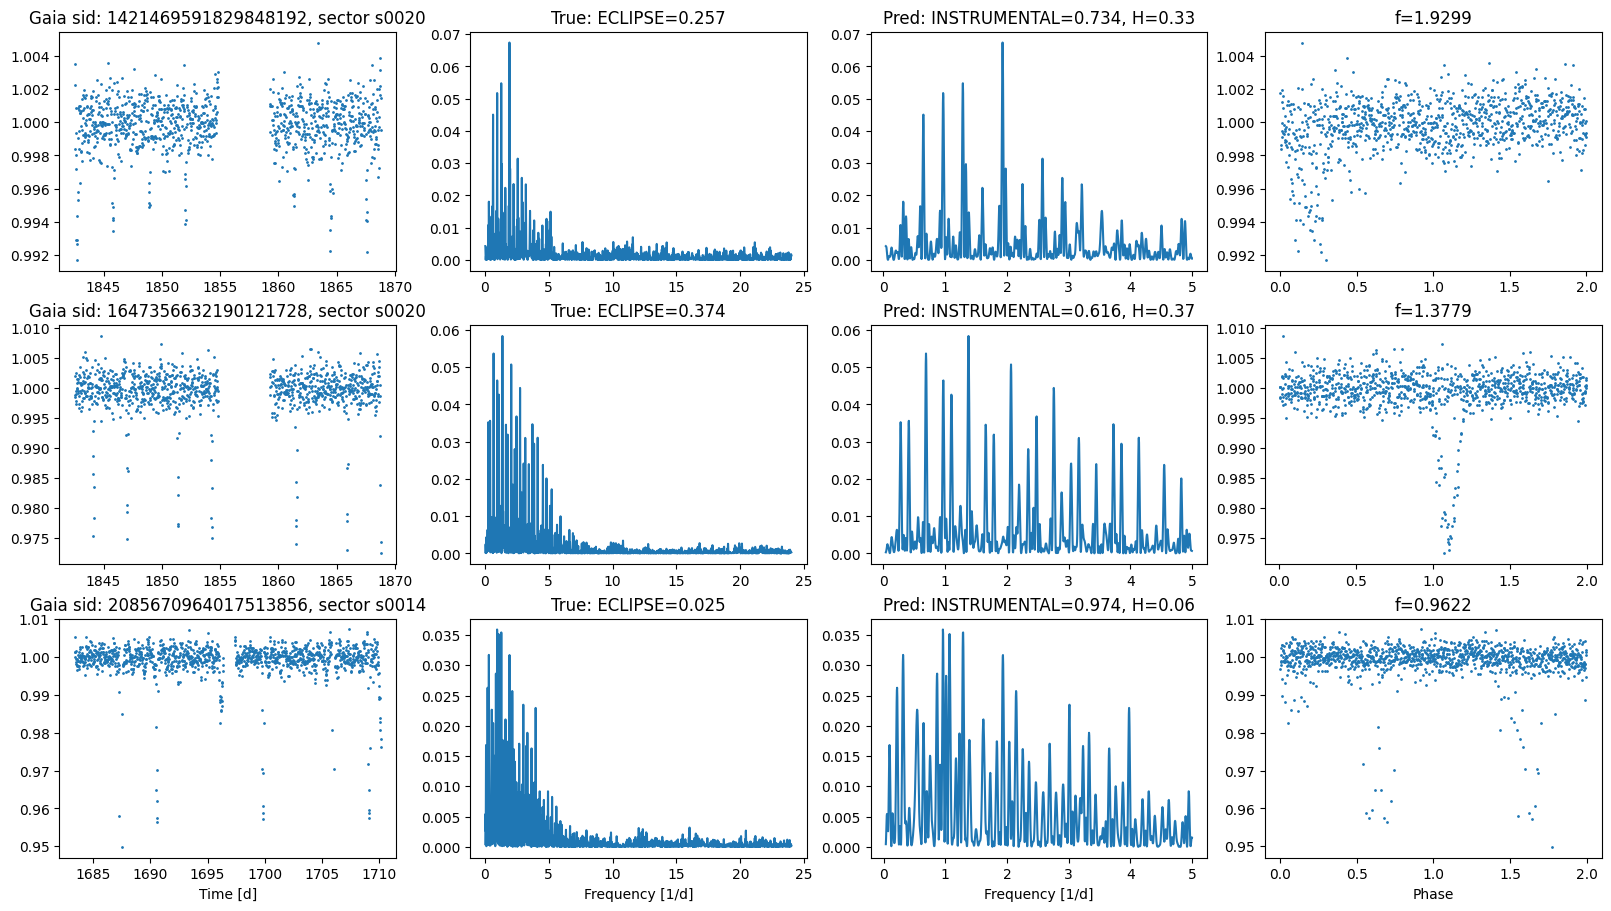

In [104]:
plot_misclasifications(true_class = 'ECLIPSE', pred_class = 'INSTRUMENTAL', max_examples=6)

Total LCs: 4, total sources: 4


path,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENTAL,RRLYR_CEPH,SOLARLIKE,best_class,entropy,best_proba,label,sid,sector
str,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,str,str,str
"""/STER/mamsie/tess/TIC/tglc_scr…",0.010088,0.001474,0.745527,0.006309,0.236454,0.000079,0.000068,"""ECLIPSE""",0.333644,0.745527,"""INSTRUMENTAL""","""1637683850443695488""","""s0016"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.002144,0.000472,0.889457,0.000056,0.107846,3.6565e-7,0.000025,"""ECLIPSE""",0.18602,0.889457,"""INSTRUMENTAL""","""2068855514216682112""","""s0014"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.001126,0.000808,0.936138,0.000047,0.061876,6.9892e-7,0.000004,"""ECLIPSE""",0.127388,0.936138,"""INSTRUMENTAL""","""2076563399970505088""","""s0041"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.40547,0.000231,0.515985,0.00084,0.07734,0.000002,0.000131,"""ECLIPSE""",0.469949,0.515985,"""INSTRUMENTAL""","""2099460008058773120""","""s0040"""


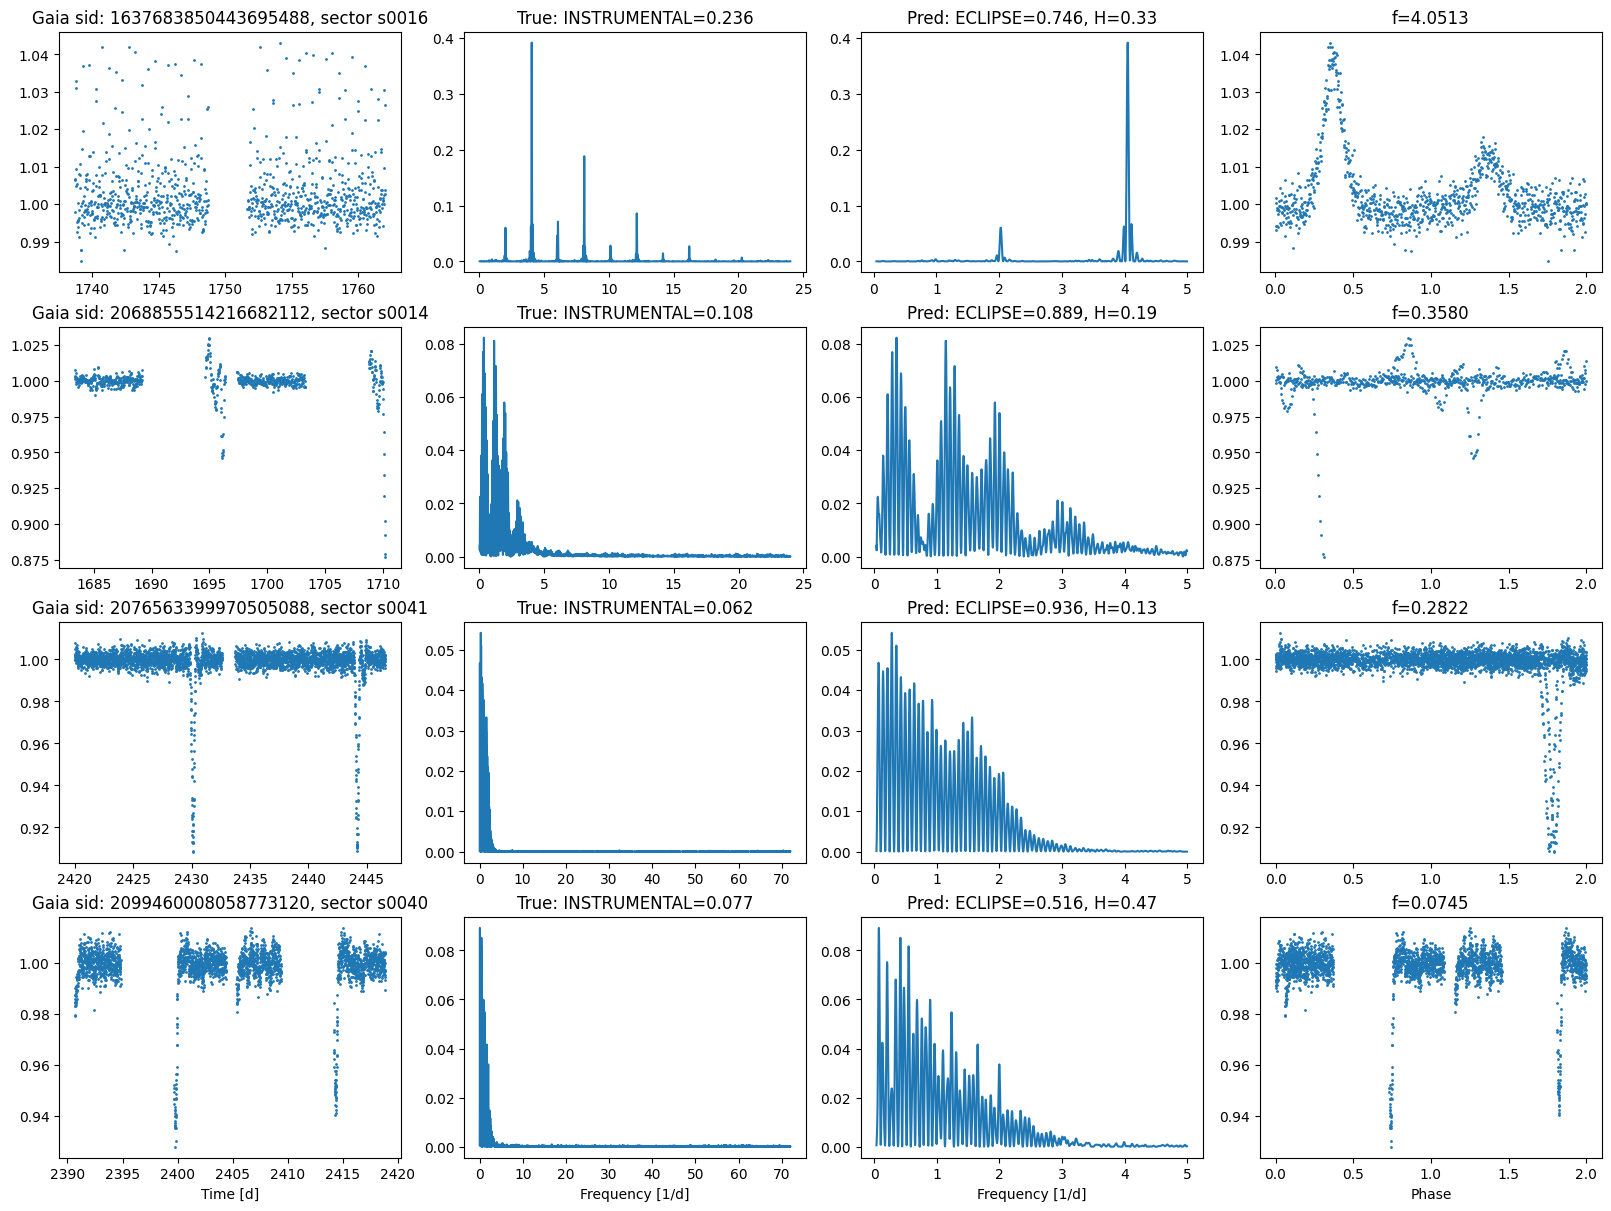

In [105]:
plot_misclasifications(true_class = 'INSTRUMENTAL', pred_class = 'ECLIPSE', max_examples=6)

Total LCs: 5, total sources: 2


path,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENTAL,RRLYR_CEPH,SOLARLIKE,best_class,entropy,best_proba,label,sid,sector
str,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,str,str,str
"""/STER/mamsie/tess/TIC/tglc_scr…",0.091567,0.00016,0.865709,0.032942,0.009576,0.000007,0.000039,"""ECLIPSE""",0.258272,0.865709,"""CONTACT_ROT""","""2073389041190882560""","""s0014"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.024532,0.000007,0.968577,0.006578,0.000268,0.000002,0.000035,"""ECLIPSE""",0.080996,0.968577,"""CONTACT_ROT""","""2131718510982169728""","""s0014"""


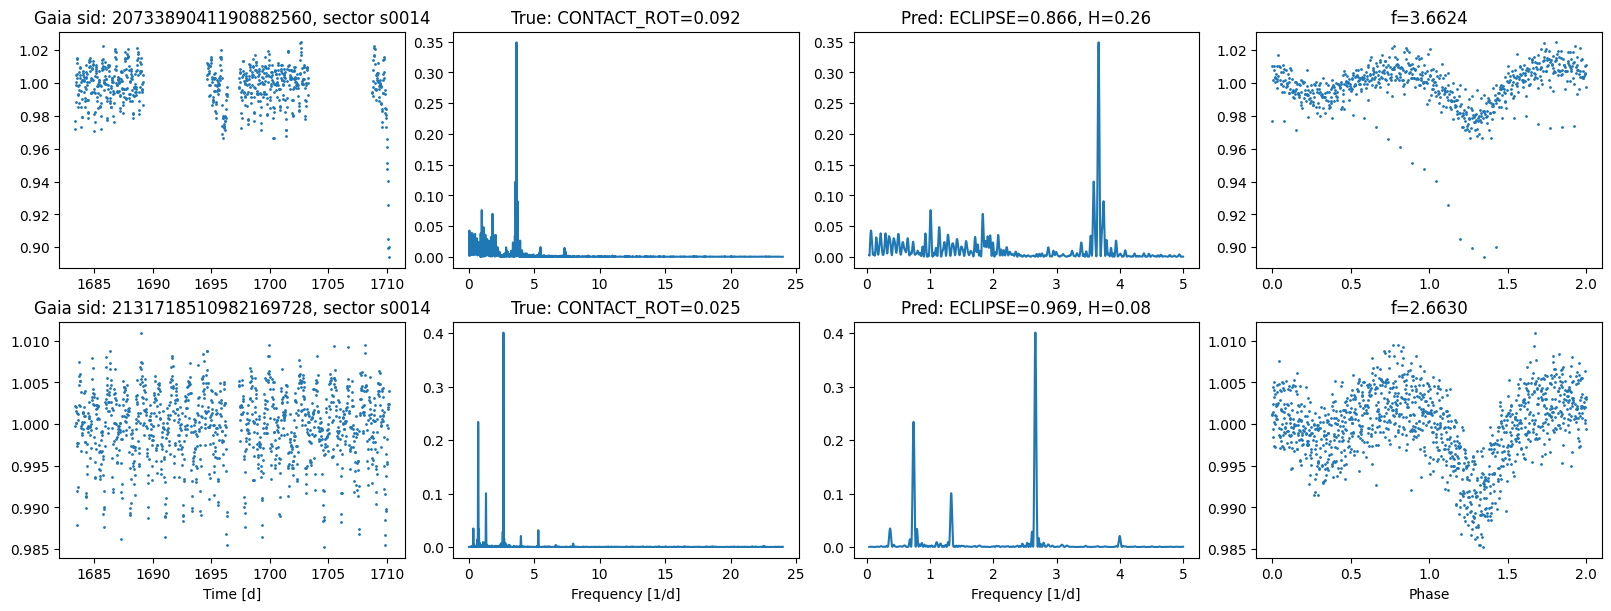

In [103]:
plot_misclasifications(true_class = 'CONTACT_ROT', pred_class = 'ECLIPSE', max_examples=6)

Total LCs: 8, total sources: 8


path,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENTAL,RRLYR_CEPH,SOLARLIKE,best_class,entropy,best_proba,label,sid,sector
str,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,str,str,str
"""/STER/mamsie/tess/TIC/tglc_scr…",0.015381,0.000232,0.000219,0.000274,0.981921,0.00001,0.001964,"""INSTRUMENTAL""",0.051653,0.981921,"""CONTACT_ROT""","""1437492882156224384""","""s0021"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.193882,0.000296,0.012546,0.122478,0.664822,0.00005,0.005927,"""INSTRUMENTAL""",0.480431,0.664822,"""CONTACT_ROT""","""1669008794984155648""","""s0014"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.49012,0.000155,0.000814,0.00771,0.493162,0.000011,0.008028,"""INSTRUMENTAL""",0.401691,0.493162,"""CONTACT_ROT""","""1862526006878465408""","""s0014"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.331392,0.000341,0.003925,0.223771,0.414461,0.000014,0.026096,"""INSTRUMENTAL""",0.609399,0.414461,"""CONTACT_ROT""","""1866484832839643392""","""s0015"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.023897,0.000024,0.000036,0.002446,0.973225,0.000003,0.000368,"""INSTRUMENTAL""",0.068827,0.973225,"""CONTACT_ROT""","""2058766258094114688""","""s0014"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.201827,0.000131,0.003693,0.001034,0.793068,0.000001,0.000244,"""INSTRUMENTAL""",0.276415,0.793068,"""CONTACT_ROT""","""2067483804739283328""","""s0014"""


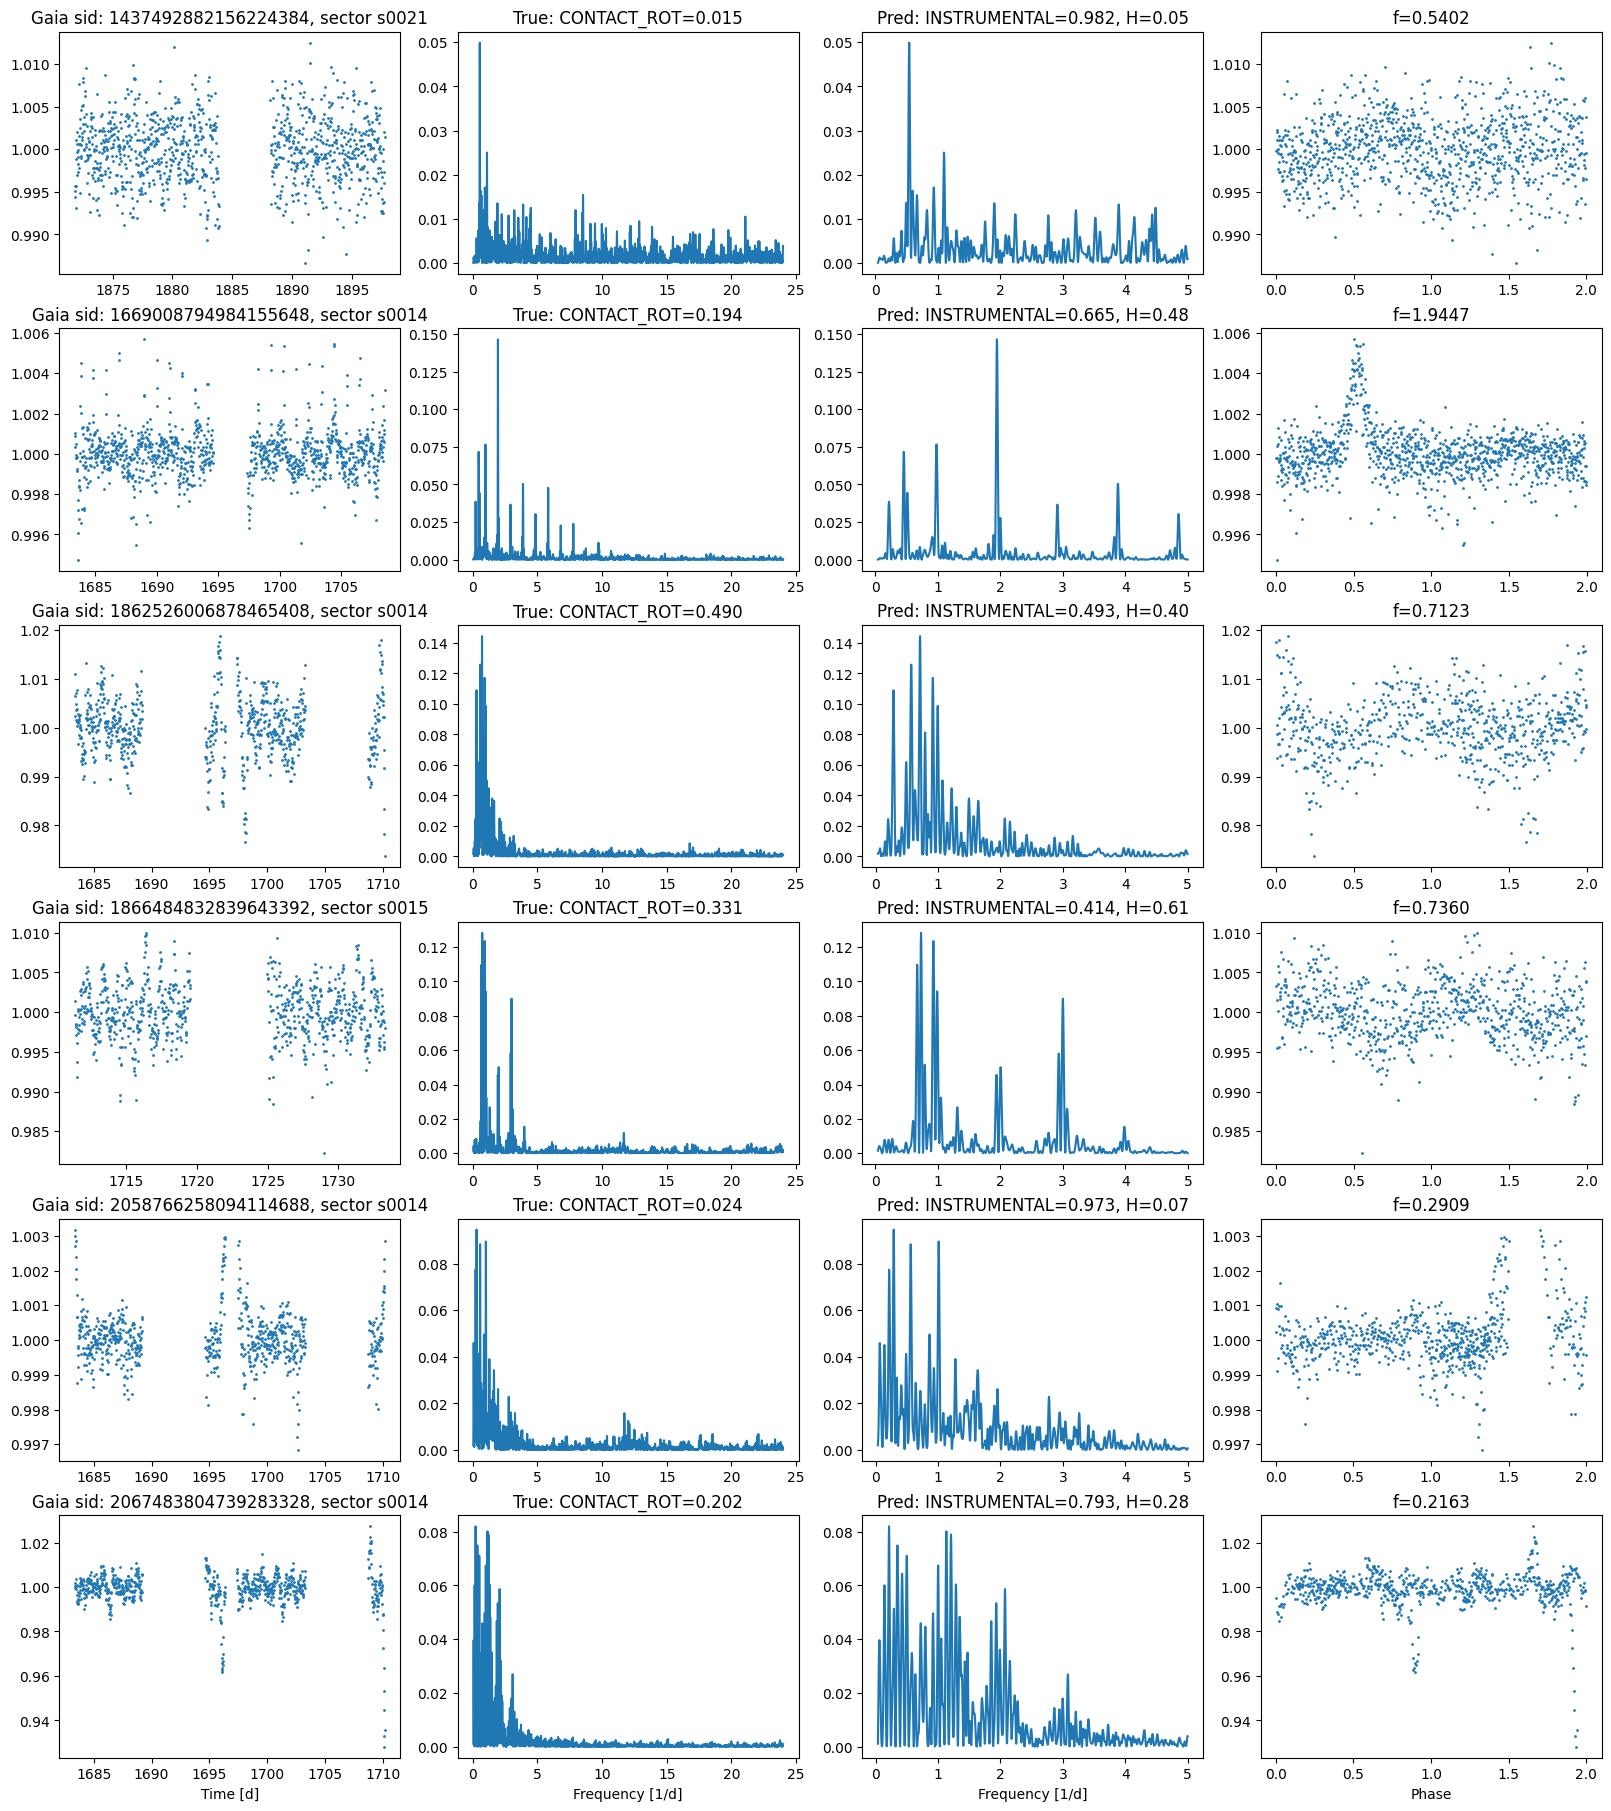

In [106]:
plot_misclasifications(true_class = 'CONTACT_ROT', pred_class = 'INSTRUMENTAL', max_examples=6)

Total LCs: 7, total sources: 6


path,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENTAL,RRLYR_CEPH,SOLARLIKE,best_class,entropy,best_proba,label,sid,sector
str,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,str,str,str
"""/STER/mamsie/tess/TIC/tglc_scr…",0.03852,0.000074,0.000137,0.872689,0.088157,0.000037,0.000387,"""GDOR_SPB""",0.238305,0.872689,"""INSTRUMENTAL""","""1422515575281437440""","""s0026"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.136876,0.005254,0.001142,0.407051,0.382923,0.000368,0.066386,"""GDOR_SPB""",0.628974,0.407051,"""INSTRUMENTAL""","""1967348497664495744""","""s0015"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.182588,0.000174,0.000555,0.408887,0.373504,0.000016,0.034277,"""GDOR_SPB""",0.598937,0.408887,"""INSTRUMENTAL""","""2050253151867756160""","""s0014"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.010447,0.001149,0.000143,0.732789,0.251671,0.000014,0.003787,"""GDOR_SPB""",0.335581,0.732789,"""INSTRUMENTAL""","""2051723645588602752""","""s0014"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.018634,0.000129,0.000022,0.682366,0.25313,0.000005,0.045714,"""GDOR_SPB""",0.424102,0.682366,"""INSTRUMENTAL""","""2117324563746199040""","""s0026"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.040067,0.000331,0.000071,0.597463,0.359652,0.000172,0.002244,"""GDOR_SPB""",0.422905,0.597463,"""INSTRUMENTAL""","""2135308794406280704""","""s0014"""


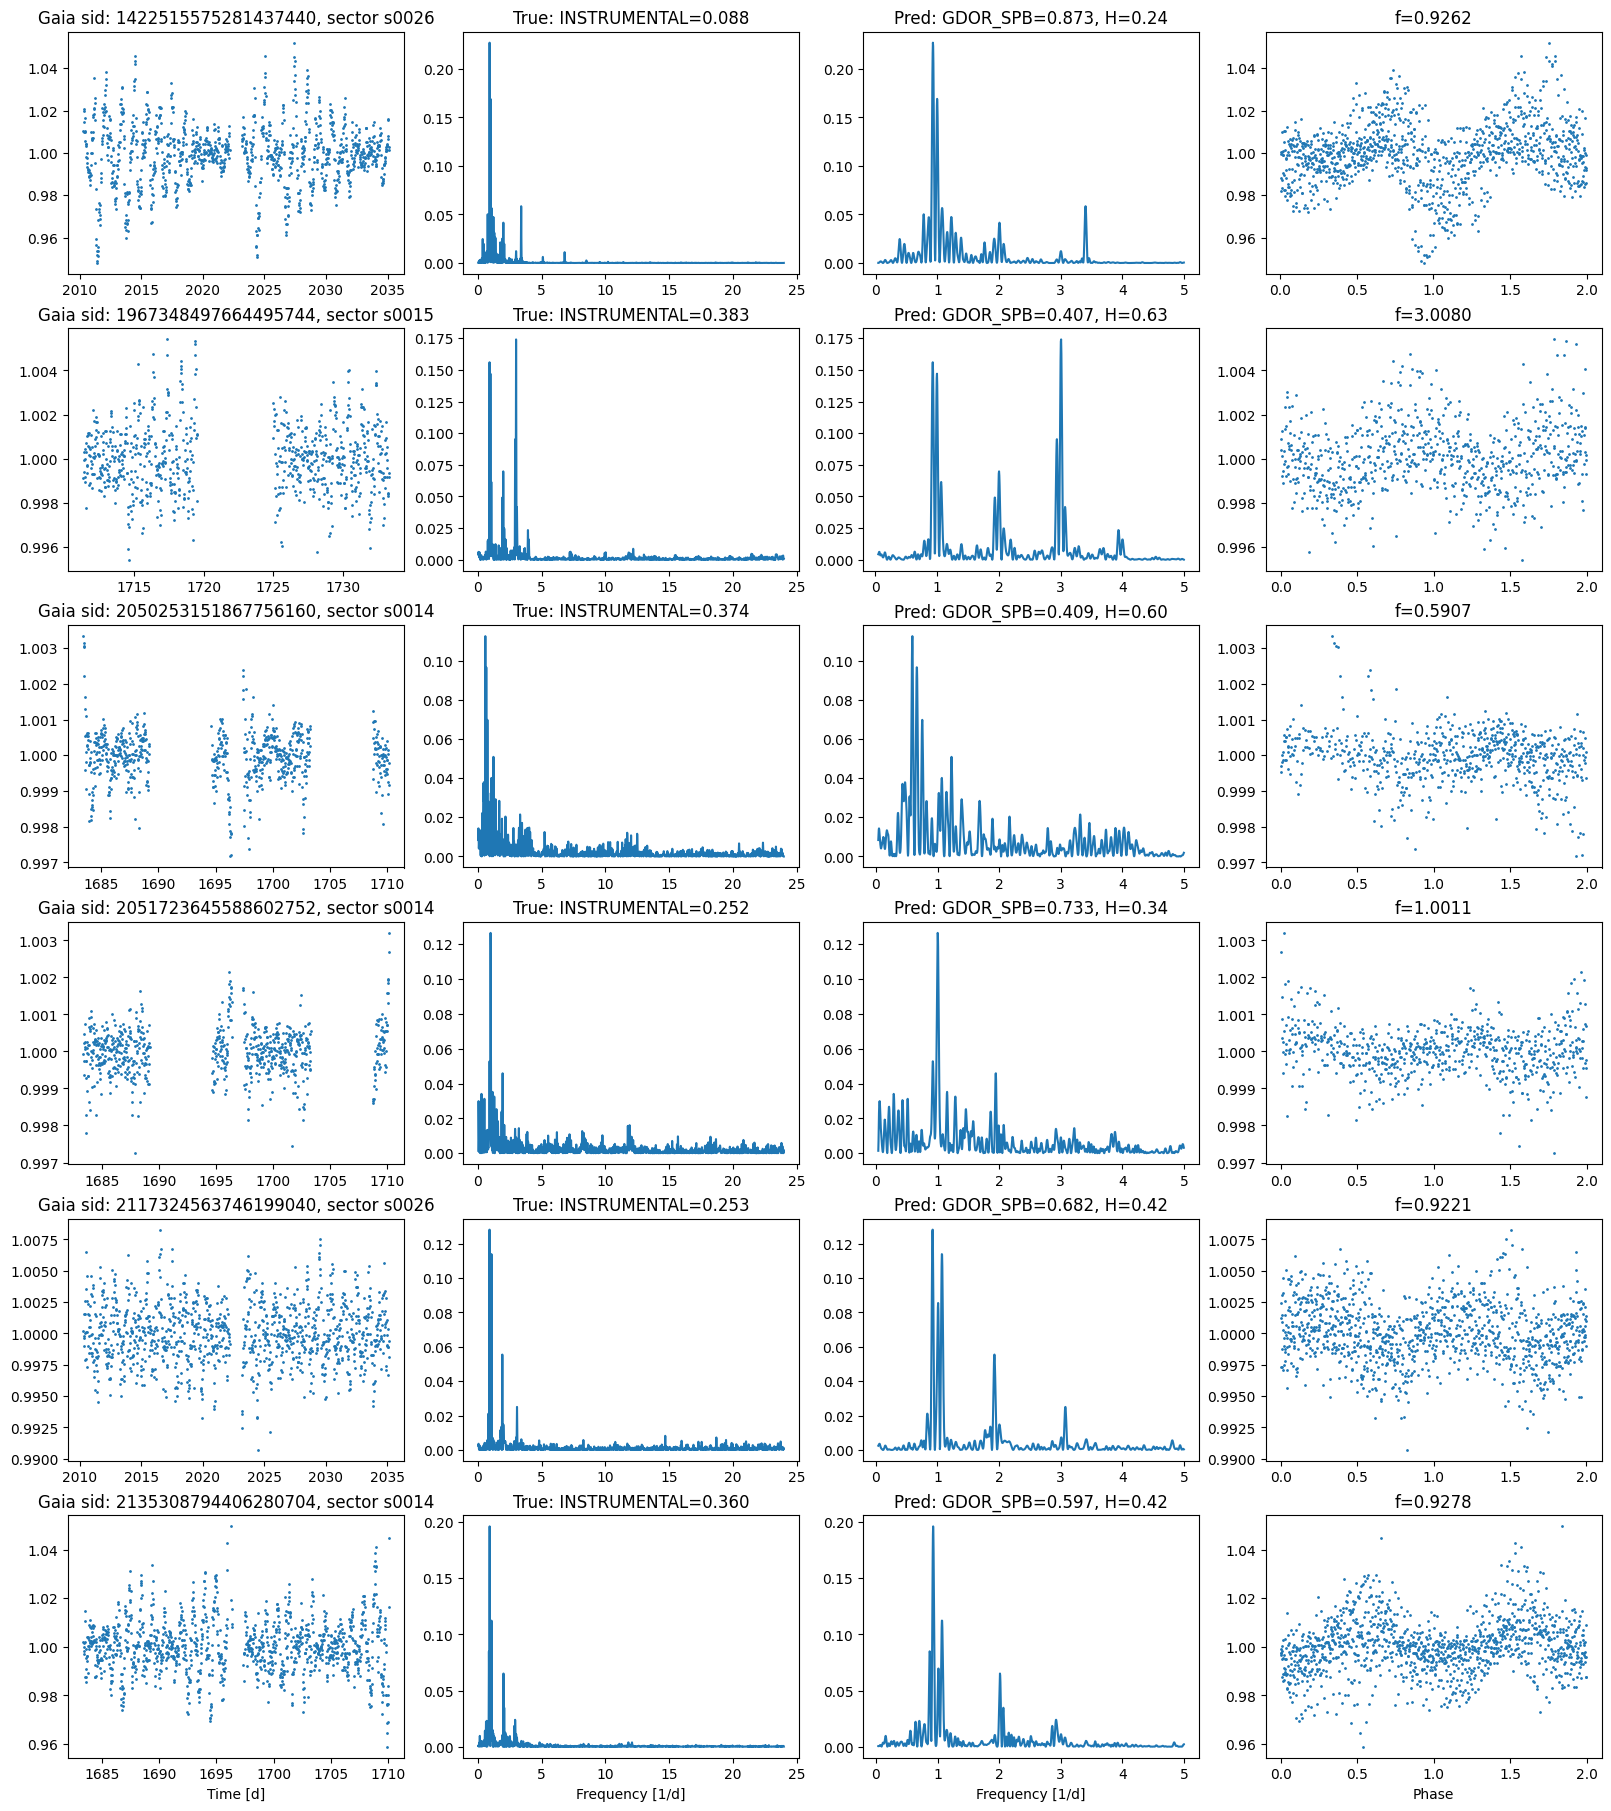

In [107]:
plot_misclasifications(true_class = 'INSTRUMENTAL', pred_class = 'GDOR_SPB', max_examples=6)

Total LCs: 6, total sources: 6


path,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENTAL,RRLYR_CEPH,SOLARLIKE,best_class,entropy,best_proba,label,sid,sector
str,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,str,str,str
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000781,0.007729,0.001653,0.428693,0.458291,0.000153,0.102701,"""INSTRUMENTAL""",0.518796,0.458291,"""GDOR_SPB""","""1649156257846877568""","""s0025"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.260112,0.002408,0.00314,0.291105,0.401604,0.01008,0.031552,"""INSTRUMENTAL""",0.649517,0.401604,"""GDOR_SPB""","""2051696570113904768""","""s0040"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.021885,0.00035,0.000201,0.443519,0.512521,0.000013,0.021512,"""INSTRUMENTAL""",0.449163,0.512521,"""GDOR_SPB""","""2077423527299215104""","""s0041"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.010534,0.000499,0.001681,0.38735,0.589338,0.000007,0.01059,"""INSTRUMENTAL""",0.405842,0.589338,"""GDOR_SPB""","""2077609688358995840""","""s0014"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.005266,0.000101,0.000011,0.347526,0.592377,0.000007,0.054712,"""INSTRUMENTAL""",0.444635,0.592377,"""GDOR_SPB""","""2079602445802257024""","""s0015"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.006583,0.000214,0.000176,0.272382,0.541137,0.000094,0.179414,"""INSTRUMENTAL""",0.530377,0.541137,"""GDOR_SPB""","""2140332428671448832""","""s0023"""


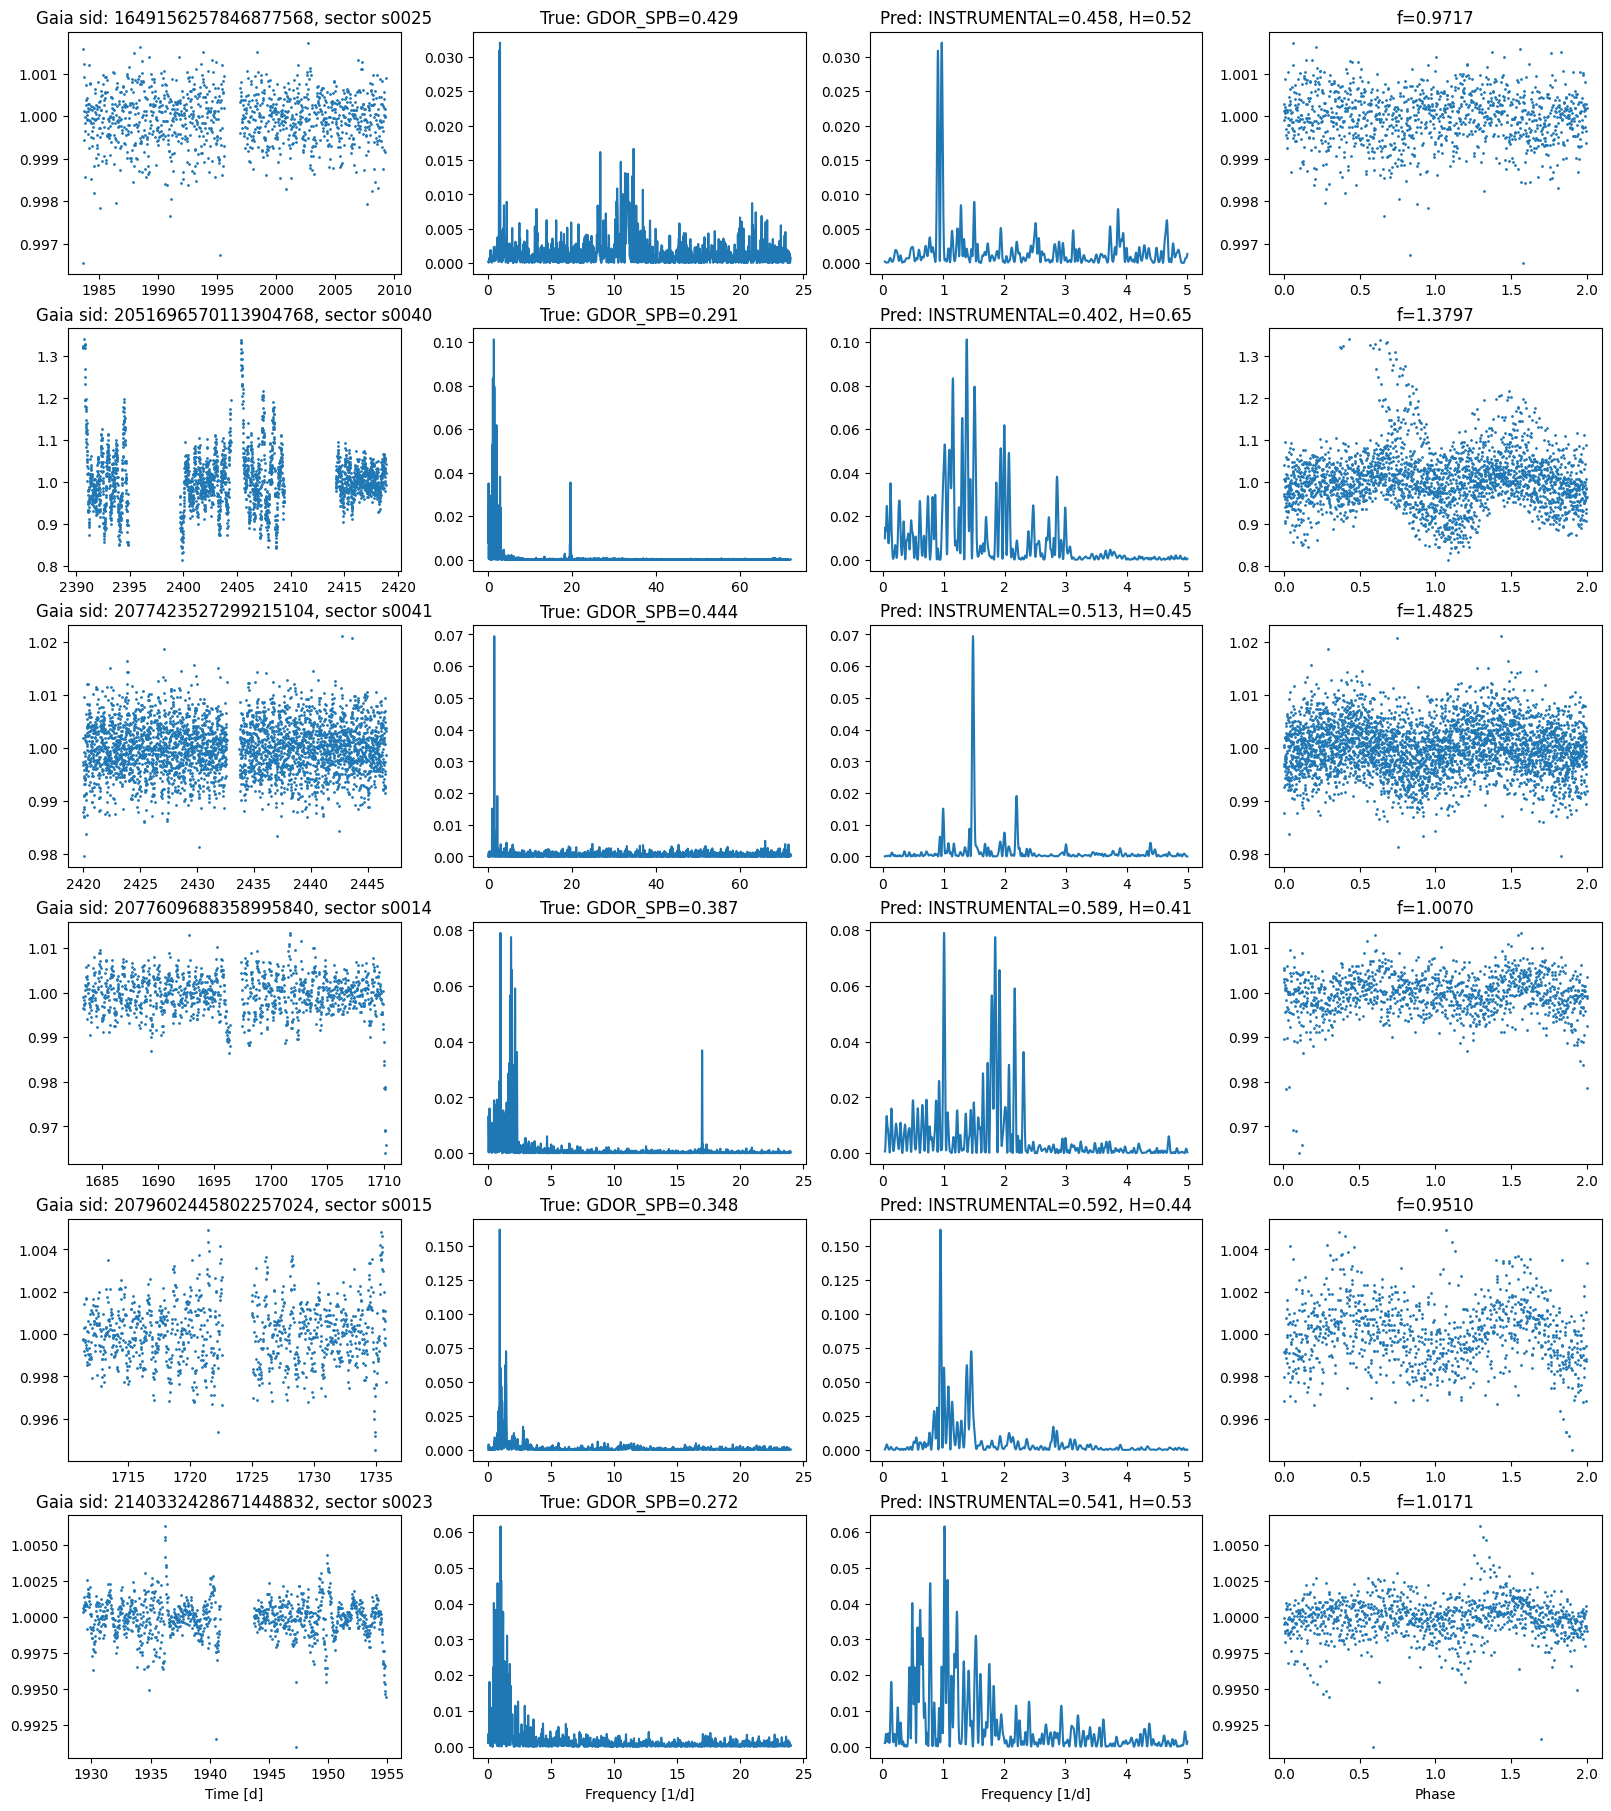

In [108]:
plot_misclasifications(true_class = 'GDOR_SPB', pred_class = 'INSTRUMENTAL', max_examples=6)

Total LCs: 20, total sources: 14


path,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENTAL,RRLYR_CEPH,SOLARLIKE,best_class,entropy,best_proba,label,sid,sector
str,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,str,str,str
"""/STER/mamsie/tess/TIC/tglc_scr…",0.001821,0.000331,0.000506,0.460094,0.018861,0.000007,0.518379,"""SOLARLIKE""",0.40636,0.518379,"""GDOR_SPB""","""1368671116479731712""","""s0021"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.002693,0.00026,0.000549,0.252328,0.018301,0.000007,0.725863,"""SOLARLIKE""",0.347152,0.725863,"""GDOR_SPB""","""1440583093946207488""","""s0023"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.001313,0.000232,0.000037,0.39202,0.016134,0.000002,0.590263,"""SOLARLIKE""",0.388466,0.590263,"""GDOR_SPB""","""1440881675776059008""","""s0017"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.00012,0.000014,0.000034,0.312029,0.000094,0.000002,0.687708,"""SOLARLIKE""",0.320341,0.687708,"""GDOR_SPB""","""1630470332610461312""","""s0023"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000578,0.000002,1.7332e-7,0.490284,0.00001,6.6094e-7,0.509125,"""SOLARLIKE""",0.358505,0.509125,"""GDOR_SPB""","""1709237387119629696""","""s0040"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000832,0.000002,0.000002,0.399132,0.000012,0.000002,0.600018,"""SOLARLIKE""",0.349035,0.600018,"""GDOR_SPB""","""2119528122485182720""","""s0040"""


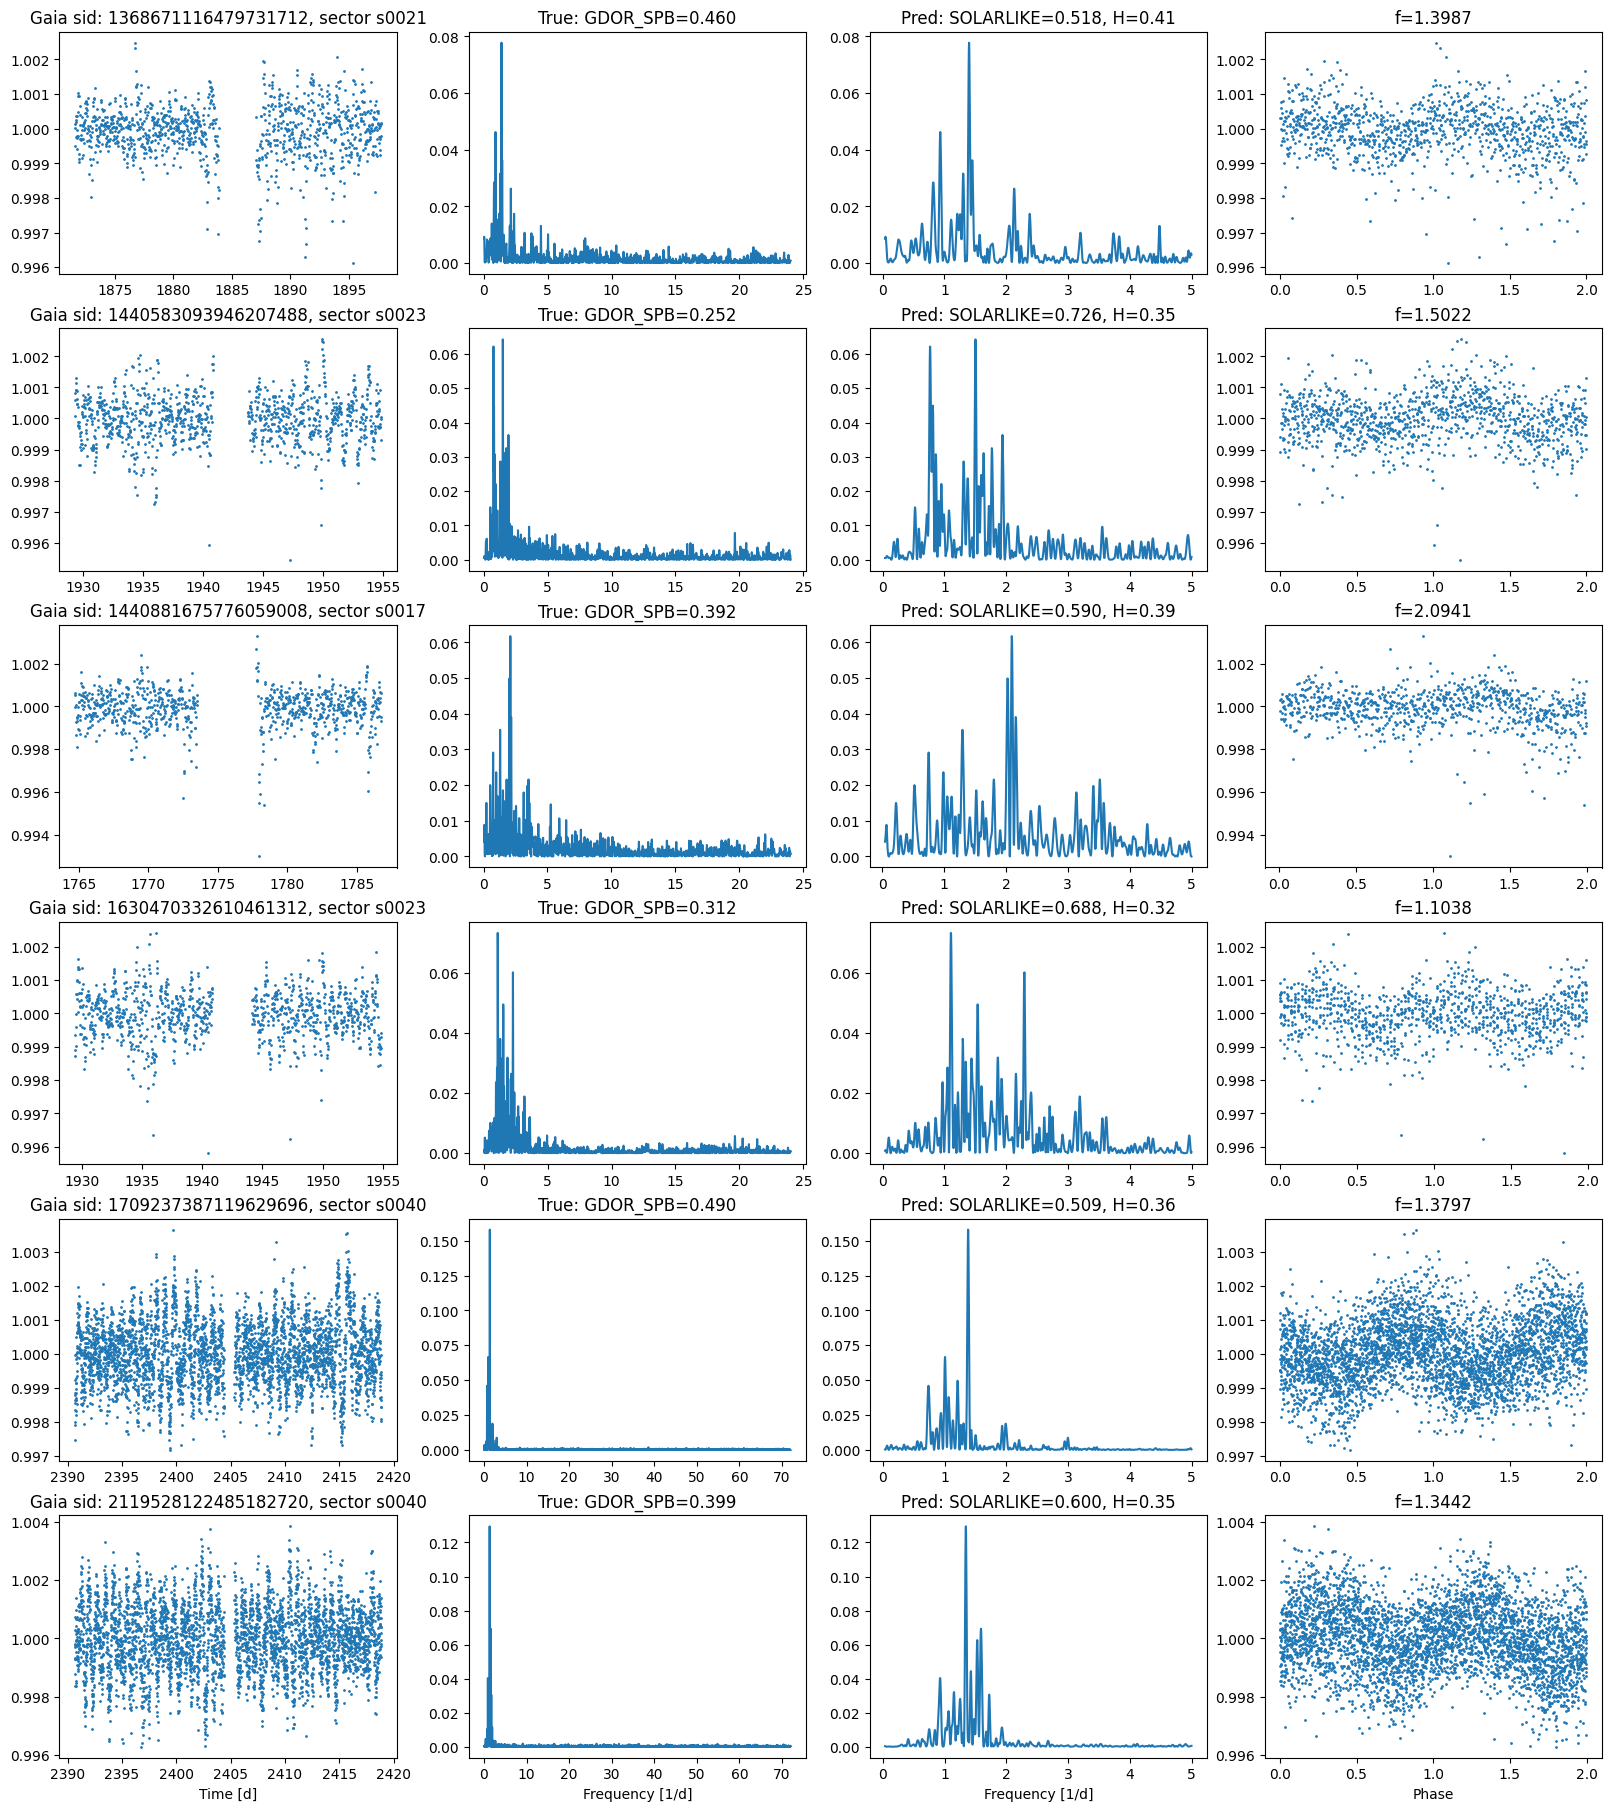

In [109]:
plot_misclasifications(true_class = 'GDOR_SPB', pred_class = 'SOLARLIKE', max_examples=6)

Total LCs: 22, total sources: 19


path,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENTAL,RRLYR_CEPH,SOLARLIKE,best_class,entropy,best_proba,label,sid,sector
str,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,str,str,str
"""/STER/mamsie/tess/TIC/tglc_scr…",0.00666,0.015832,0.000049,0.521049,0.001966,0.000007,0.454438,"""GDOR_SPB""",0.416216,0.521049,"""SOLARLIKE""","""1417341479719191168""","""s0017"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000214,0.000956,0.000626,0.57042,0.044577,0.000008,0.383199,"""GDOR_SPB""",0.431477,0.57042,"""SOLARLIKE""","""1561637640537538048""","""s0023"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.004742,0.002523,0.008408,0.613913,0.170033,0.000008,0.200373,"""GDOR_SPB""",0.515771,0.613913,"""SOLARLIKE""","""1642555683386893184""","""s0018"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000346,0.000086,0.00001,0.608495,0.00006,0.000007,0.390996,"""GDOR_SPB""",0.346262,0.608495,"""SOLARLIKE""","""1655477040957291520""","""s0018"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000338,0.000454,0.000017,0.557909,0.000033,0.000002,0.441248,"""GDOR_SPB""",0.356298,0.557909,"""SOLARLIKE""","""1720741882222648320""","""s0021"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.002534,0.000726,0.000035,0.854236,0.000984,0.000003,0.141481,"""GDOR_SPB""",0.225536,0.854236,"""SOLARLIKE""","""1853908859366244096""","""s0015"""


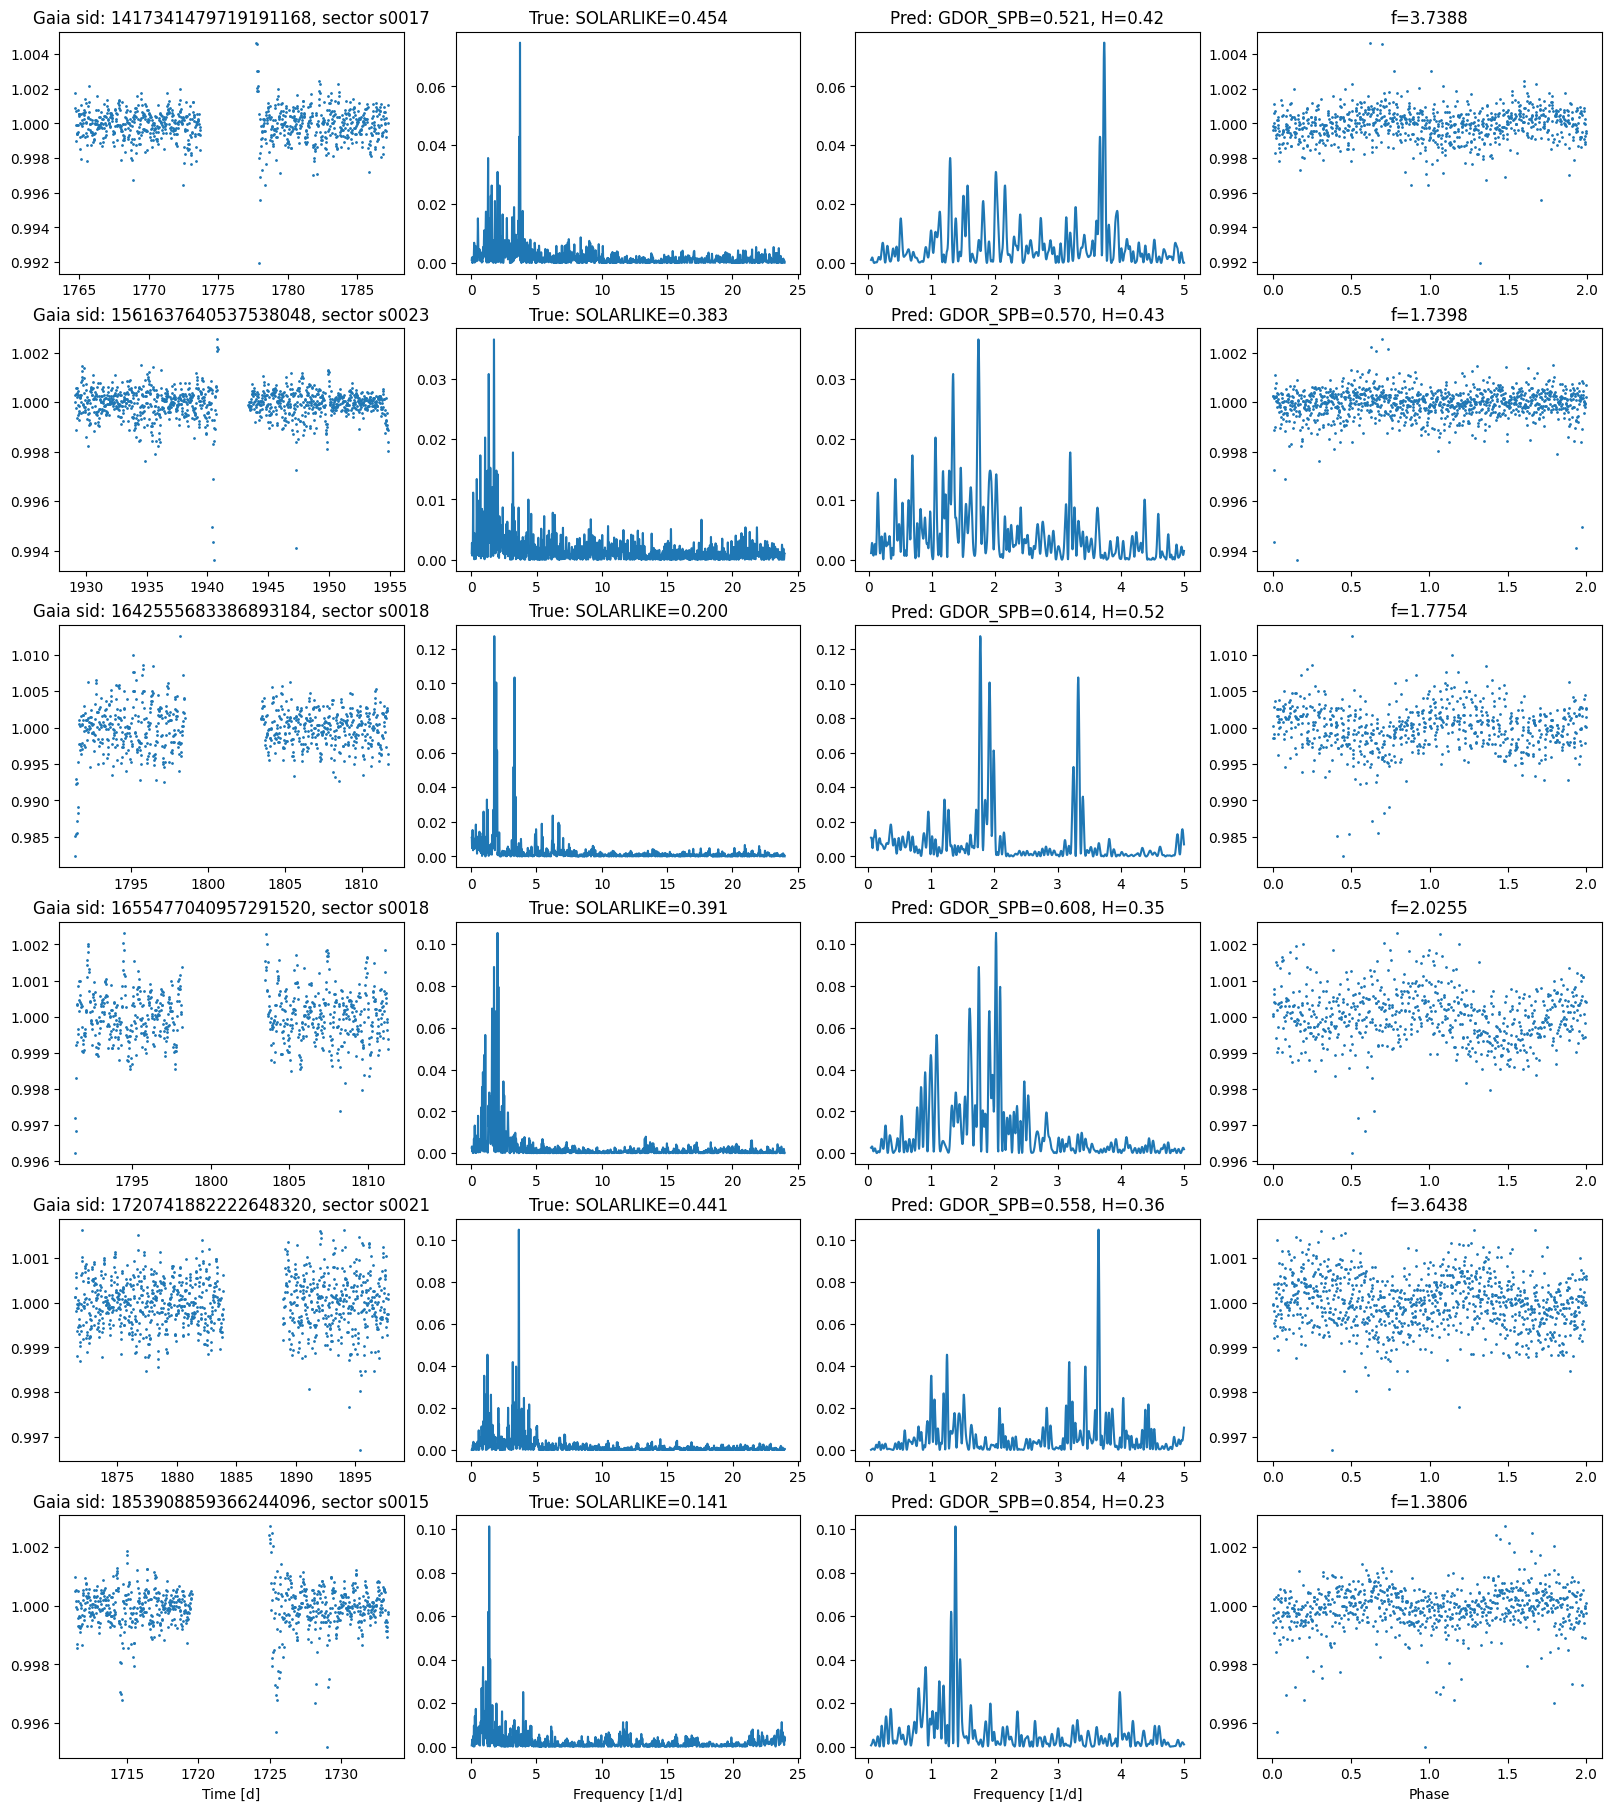

In [110]:
plot_misclasifications(true_class = 'SOLARLIKE', pred_class = 'GDOR_SPB', max_examples=6)

146


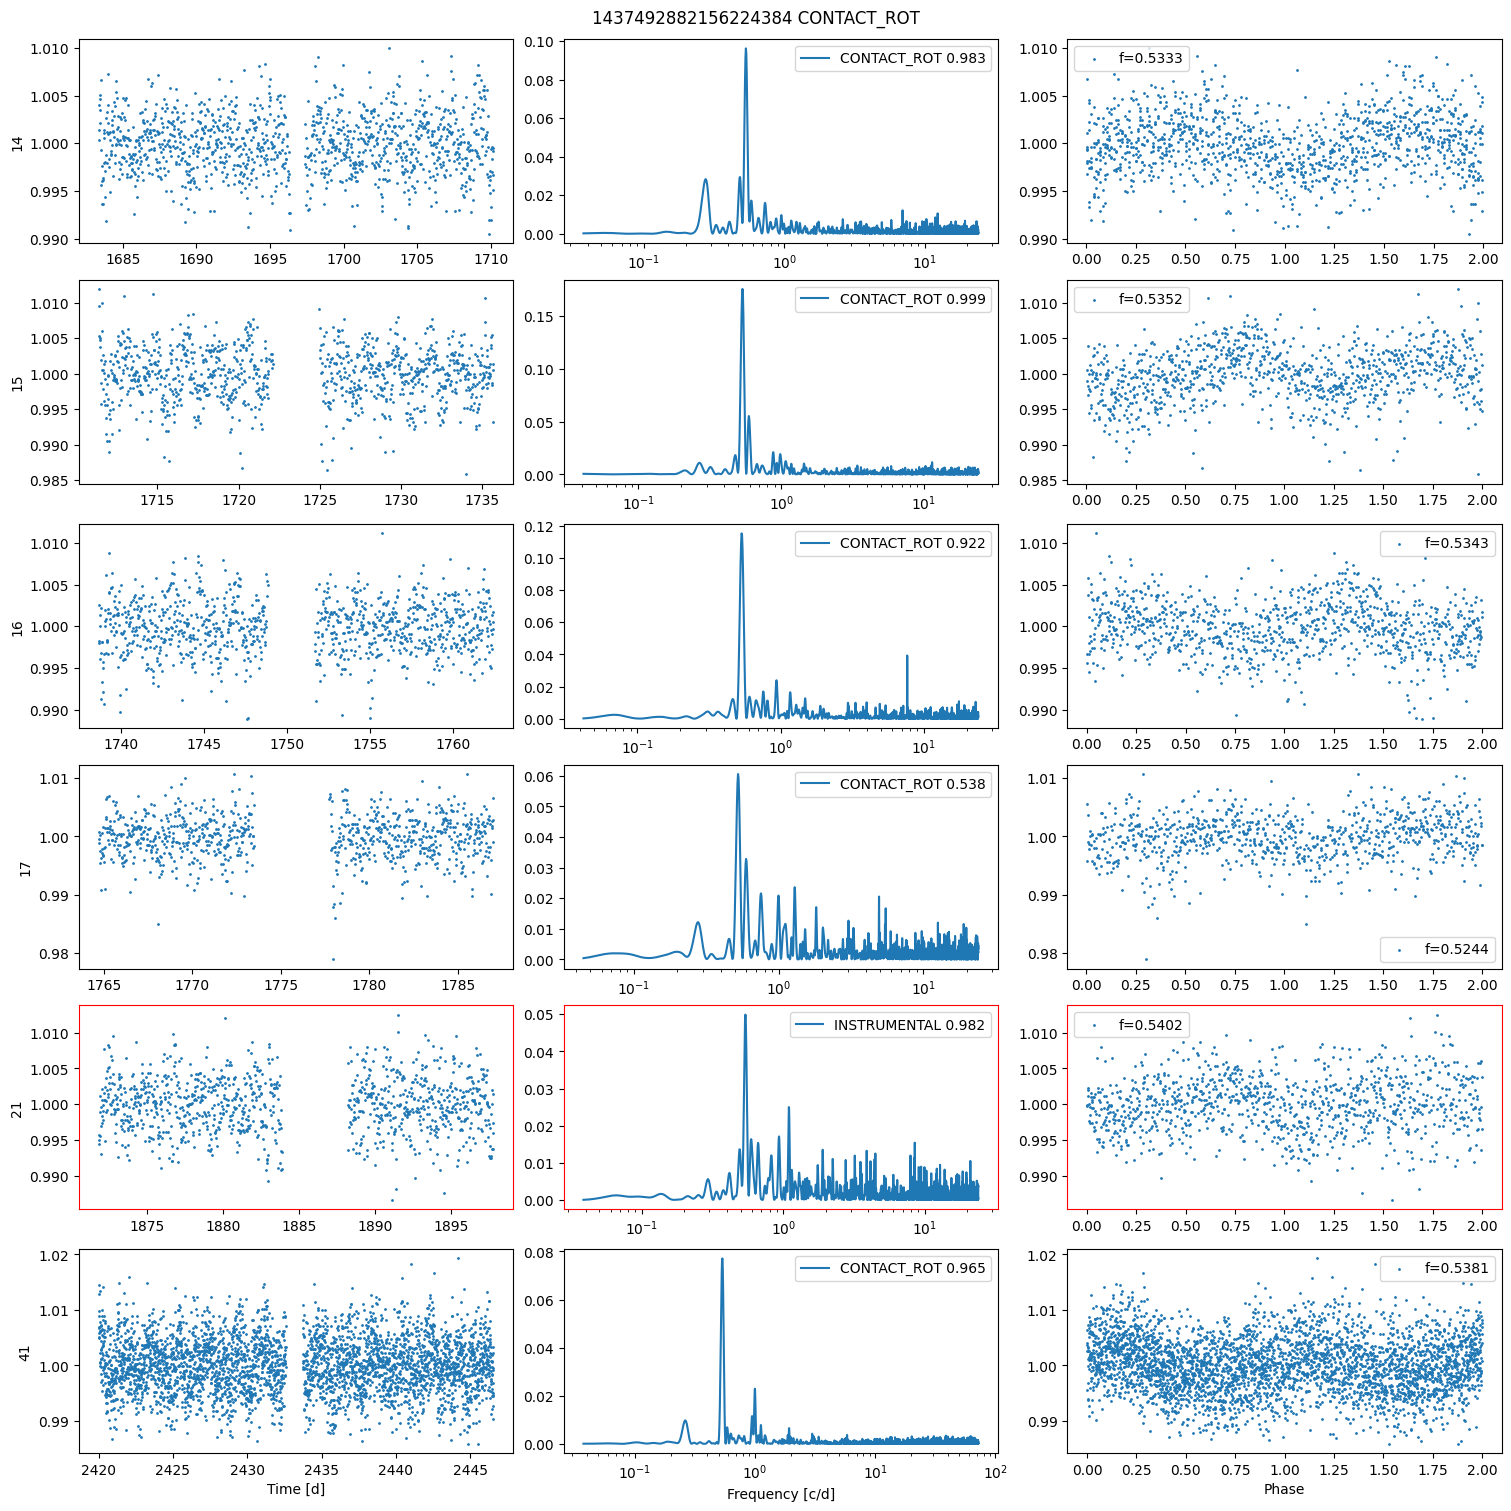

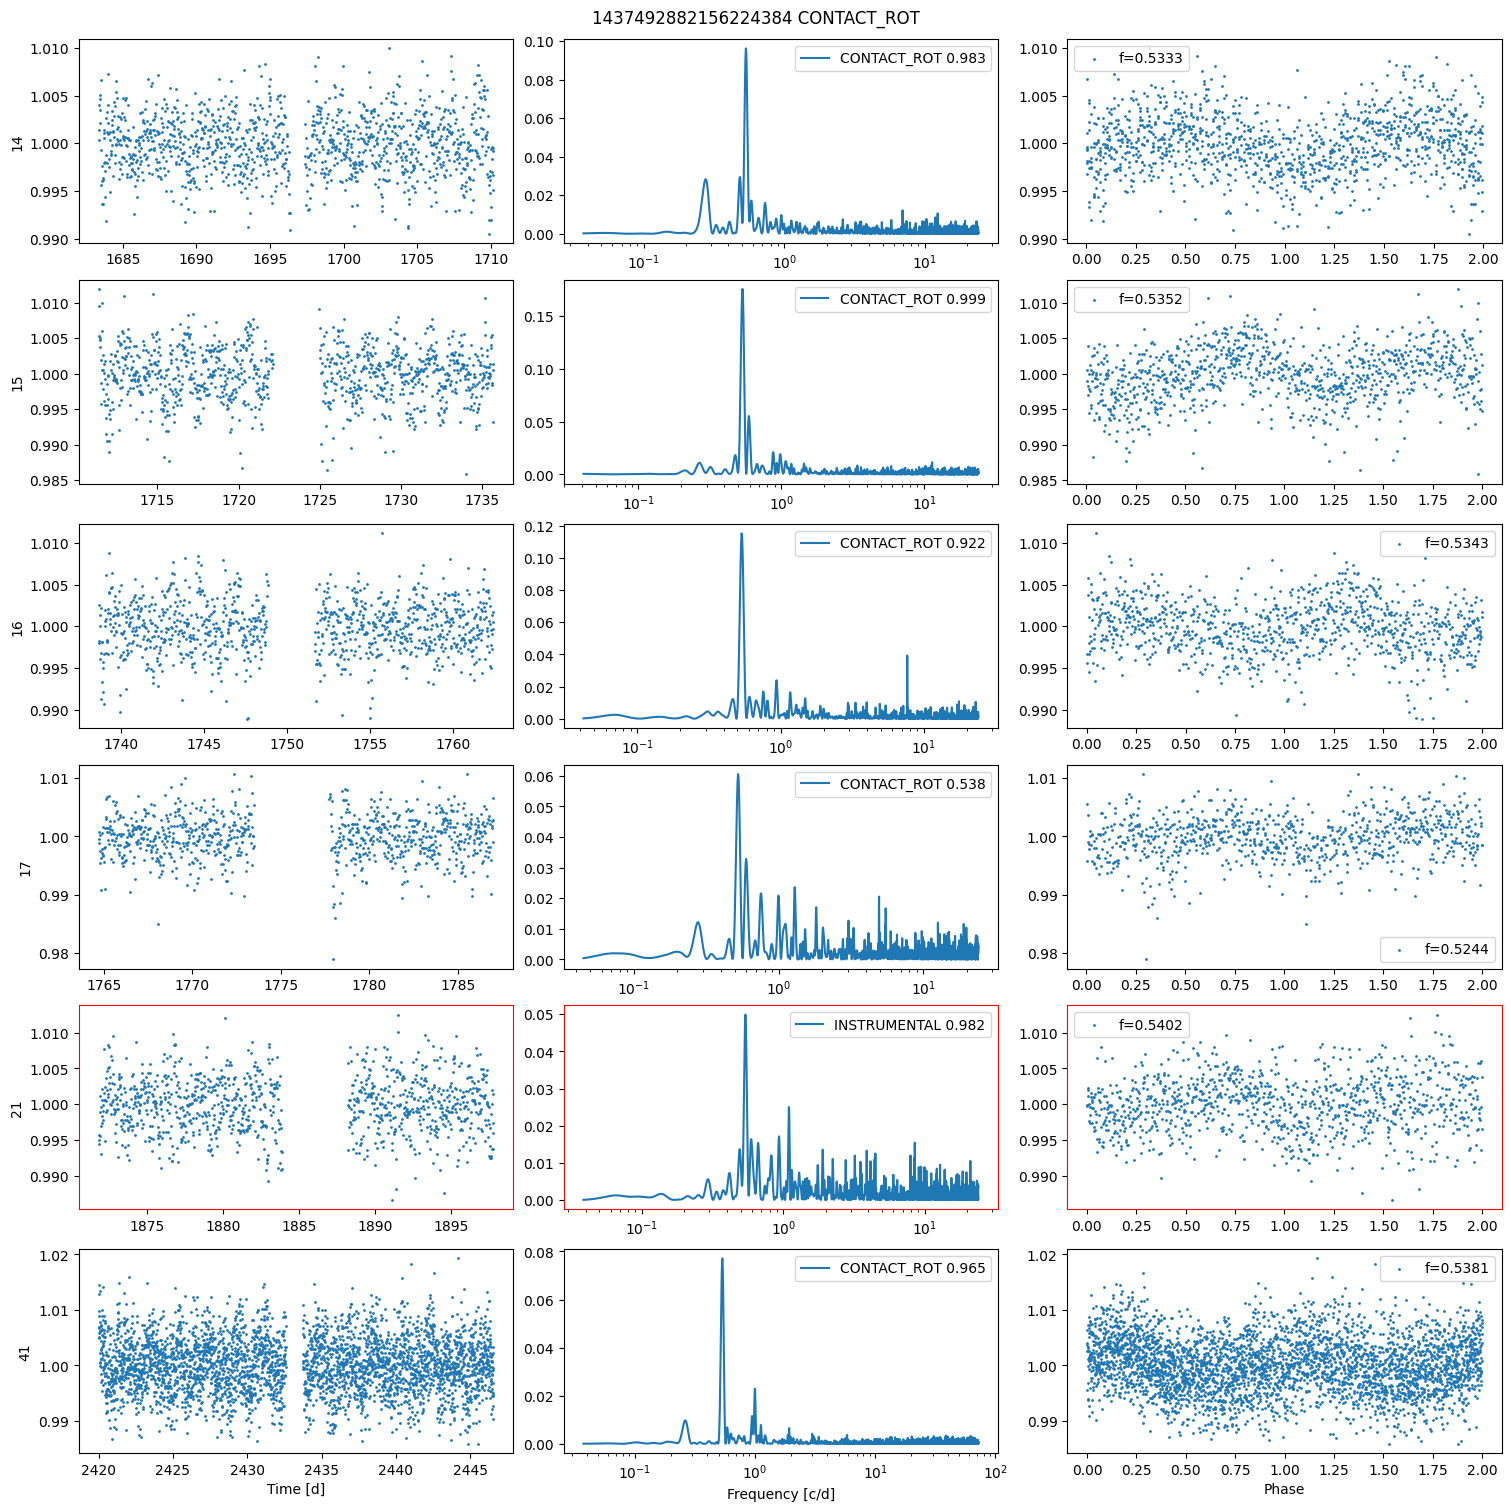

In [111]:
import matplotlib

df_analysis = df_pred.join(df_training_set.select(['path','label', 'GaiaID', 'sector']), on='path')

sources_w_errors = df_analysis.filter(
    pl.col('label').ne(pl.col('best_class')) & pl.col('best_proba').gt(0.25)
).unique('GaiaID').sort(['label', 'GaiaID'])['GaiaID'].to_list()
print(len(sources_w_errors))

def plot_sectors(subdf):
    fig, axs = plt.subplots(subdf.height, 3, figsize=(15, 2.5*subdf.height), constrained_layout=True)
    axs = np.atleast_2d(axs)
    for ax, row in zip(axs, subdf.sort('sector').iter_rows(named=True)):
        lc = read_fits_lc(row['path'])
        time, flux = lc.time, lc.cal_flux
        time, flux = preprocess_lc(time, flux, row['sector'], cfg.preprocessing)
        ax[0].scatter(time, flux, s=1, rasterized=True)
        if row['label'] != row['best_class']:
            for ax_ in ax:
                ax_.spines['bottom'].set_color('red')
                ax_.spines['top'].set_color('red')
                ax_.spines['right'].set_color('red')
                ax_.spines['left'].set_color('red')
        freq, ampl, *_ = compute_periodogram(time, flux)
        ax[1].plot(freq, ampl, label=f"{row['best_class']} {row['best_proba']:0.3f}", rasterized=True)
        ax[1].legend(fontsize=10)
        ax[1].set_xscale('log')
        best_freq = freq[np.argmax(ampl)]
        ax[2].scatter(np.mod(time, 2/best_freq)*best_freq, flux, s=1, label=f"f={best_freq:0.4f}", rasterized=True)
        ax[2].legend(fontsize=10)
        ax[0].set_ylabel(row['sector'])
        del freq, ampl
    ax[0].set_xlabel('Time [d]')
    ax[1].set_xlabel('Frequency [c/d]')
    ax[2].set_xlabel('Phase')
    fig.suptitle(f"{row['GaiaID']} {row['label']}")
    return fig

plot_sectors(df_analysis.filter(pl.col('GaiaID').eq(sources_w_errors[0])))

In [129]:
tmpdir = Path("mistakes_tmp")
tmpdir.mkdir(exist_ok=True)

for p in tmpdir.iterdir():
    p.unlink()
tmpdir.rmdir()

In [130]:
from pypdf import PdfWriter
from tqdm.notebook import tqdm
import gc

tmpdir = Path("mistakes_tmp")
tmpdir.mkdir(exist_ok=True)

for sid in tqdm(sources_w_errors):
    if (tmpdir / f"{sid}.pdf").exists():
        continue
    fig = plot_sectors(df_analysis.filter(pl.col('GaiaID').eq(sid)))
    fig.savefig(tmpdir / f"{sid}.pdf", dpi=150)
    fig.clf()
    plt.close(fig)
    gc.collect()
        
writer = PdfWriter()
for sid in sources_w_errors:
    writer.append(tmpdir / f"{sid}.pdf")
with open("mistakes_v13.pdf", "wb") as f:
    writer.write(f)

  0%|          | 0/146 [00:00<?, ?it/s]

In [114]:
df_analysis.filter(
    pl.col('label').ne(pl.col('best_class')) & pl.col('best_proba').gt(0.75)
).write_parquet(save_path / 'df_errors.parquet')

# SHAP explanations

In [ ]:
sids_all = np.array([int(p.split('-')[2]) for p in paths_all])
#np.where((sids_all == 2053065530810722432) & (sector_all == 15))[0]
examples = np.where((sids_all == 2053065530810722432) )[0]
examples, sector_all[examples]

Predicted class: 3


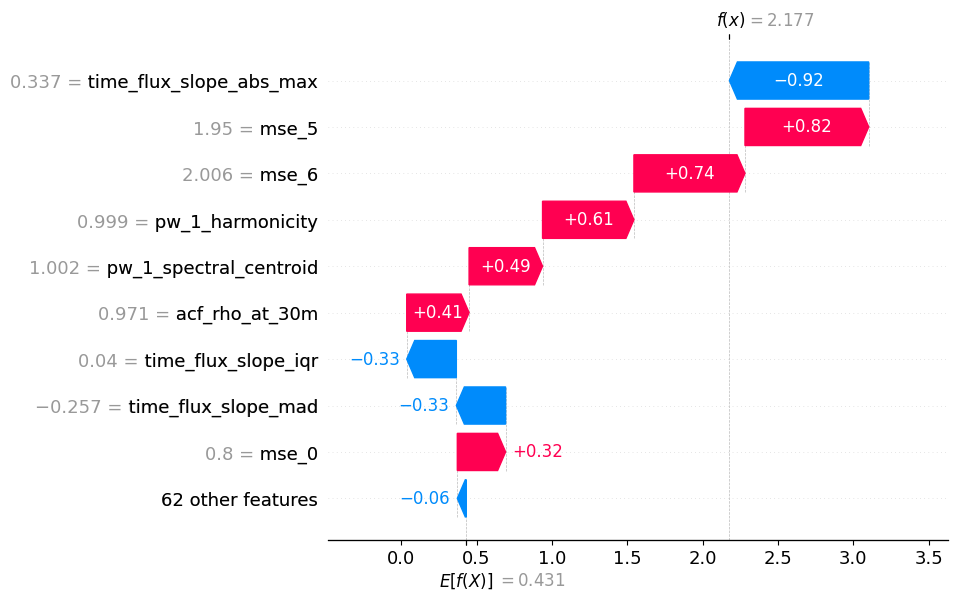

In [126]:
import shap

booster = final_clf.get_booster()
import xgboost as xgb

single_example = X_all[examples[-1], :].reshape(1, -1)
single_dmatrix = xgb.DMatrix(single_example)
contribs = booster.predict(single_dmatrix, pred_contribs=True)
predicted_class = final_clf.predict(single_example)[0]
print("Predicted class:", predicted_class)
predicted_class = 0

# Then use that as class_index
shap_values = contribs[0, predicted_class, :-1]
base_value  = contribs[0, predicted_class, -1]

explanation = shap.Explanation(
    values=shap_values,
    base_values=base_value,
    data=single_example[0],
    feature_names=X_names 
)

shap.plots.waterfall(explanation)